# Tensor networks as machine-learning models

**Marcin Płodzień** — Institute of Theoretical Physics, Jagiellonian University in Kraków  
[ORCID 0000-0002-0835-1644](https://orcid.org/0000-0002-0835-1644) · [github.com/MarcinPlodzien](https://github.com/MarcinPlodzien) · [www](https://chaos.if.uj.edu.pl/marcinplodzien/)

*Quantum Many-Body Simulation — Chapter 13 — Quantum machine learning*

## 1. Introduction

The matrix product state (MPS) classifier was introduced in [[1]](#ref-1). Training it by automatic differentiation
of the whole contraction was described in [[2]](#ref-2), and the entanglement of the data and of trained models was
studied in [[3]](#ref-3). This notebook implements the model and both training methods with matrix product state tools,
and compares its results with those of [[1]](#ref-1), [[2]](#ref-2) and [[3]](#ref-3).

The model is a **classical** classifier. It borrows its mathematics from quantum many-body physics (product states,
matrix product states, singular value decompositions, sweeps) and runs on an ordinary CPU; no quantum hardware and no
quantum algorithm is involved.

### 1.1 A classifier is a function of many pixels

A grey-scale image of $14\times14$ pixels is a list of $N=196$ numbers $x_j\in[0,1]$, with $0$ for a white and $1$
for a black pixel. Throughout the notebook pixels, sites of the chain and image rows are counted from 0, as in the code:
$j=0,1,\dots,N-1$. A *classifier* assigns to every image $\mathbf x=(x_0,\dots,x_{N-1})$ one of ten labels
$\ell\in\{0,1,\dots,9\}$, the digit that the image shows. It is a function of 196 variables, chosen from a family of
functions by fitting free parameters to examples (the *training set*) and judged by the fraction of correct labels on
images it has not seen (the *test set*).

A simple family is that of linear models: compute ten scores $f^\ell(\mathbf x)=\sum_j w^\ell_jx_j+b^\ell$ and pick
the label with the largest score. Linear models are cheap and easy to train, but they cannot represent the
correlations between pixels that distinguish, for instance, a 4 from a 9. Kernel methods keep the convenience of a
linear model and gain expressivity by first mapping $\mathbf x$ to a *feature vector* $\Phi(\mathbf x)$ in a much
larger space and then forming a linear function of $\Phi(\mathbf x)$ ([[1]](#ref-1), Eq. (1)):

$$f^\ell(\mathbf x)=W^\ell\cdot\Phi(\mathbf x). \tag{1}$$

### 1.2 The weight tensor and the exponential wall

The feature map of [[1]](#ref-1) turns every pixel into a two-component vector $\phi(x_j)$, a qubit, and the
image into the tensor product of these vectors, $\Phi(\mathbf x)=\phi(x_0)\otimes\cdots\otimes\phi(x_{N-1})$. This is a
*product state* of $N$ qubits, a vector with $2^N$ components. The weight vector $W^\ell$ of Eq. (1) then has $2^N$
components for each label: a tensor $W^\ell_{s_0s_1\cdots s_{N-1}}$ with one index per pixel. For $N=196$ that is
$10\times2^{196}\approx10^{60}$ numbers, which no computer can store.

The same exponential wall appears in many-body physics: a many-body wave function $\psi[s_0,\dots,s_{N-1}]$ of $N$ spins
also has $2^N$ components. A weakly entangled wave function is compressed into a matrix product
state with $O(N\chi^2)$ numbers, where the bond dimension $\chi$ limits the entanglement across every cut of the chain.
The idea of [[1]](#ref-1) is to apply the same compression to the weight tensor: write $W^\ell$ as an MPS, with
one extra index $\ell$ on one of its tensors, and train the MPS tensors. The model then costs $O(N\chi^2)$ numbers and
$O(N\chi^2)$ operations per image, and its expressivity is controlled by $\chi$.

Two questions follow, and the notebook answers both with numbers. How well does such a model classify, as a function
of $\chi$ and of the size of the training set? And how much entanglement does a trained classifier carry, compared
with the states that the data themselves define?

### 1.3 Road map

* **Section 3** loads a $14\times14$ version of the MNIST handwritten digits stored with this course.
* **Section 4** maps images to product states: the cosine–sine map of [[1]](#ref-1), its kernel, and the linear map
  used in [[2]](#ref-2).
* **Section 5** builds the MPS classifier, contracts it in $O(N\chi^2)$ per image, checks it against the full
  weight tensor on a small example, and rescales the contraction to avoid overflow.
* **Section 6** trains the classifier with the sweeping algorithm of [[1]](#ref-1), which is the two-site DMRG
  algorithm applied to a classification cost.
* **Section 7** trains it by automatic differentiation of the whole contraction, as in [[2]](#ref-2), shows that the
  gradient of a contraction is an environment, and discusses initialisation, normalisation, SVD gradients and memory.
* **Section 8** measures test accuracy against bond dimension and training-set size and compares with
  [[1]](#ref-1) and [[2]](#ref-2); **Section 9** studies the entanglement of the data and of the trained model
  following [[3]](#ref-3).
* **Sections 10–11** give the cost of the computation and the limits of the method.

### What you will learn

*Physics*

* how an image becomes a product state of one qubit per pixel, and why two different images are almost orthogonal;
* how the bond dimension of an MPS limits the entanglement of the weight tensor, and what that means for a classifier;
* why the equal superposition of the training images of one class is far too entangled to be the state a trained
  MPS classifier represents.

*Numerical methods*

* the MPS classifier with a label index, its contraction in $O(N\chi^2)$ per image and its parameter count;
* the sweeping algorithm: two-site bond tensor, cached environments of the data, a local gradient step with a step
  size from the largest eigenvalue, SVD split with truncation, moving label index;
* reverse-mode automatic differentiation of a tensor-network contraction, and its relation to environments;
* cross-entropy training with Adam, test accuracy, confusion matrices; Schmidt spectra of sums of product states from
  Gram matrices.

*Implementation practice*

* environments stored as stacked arrays and whole half-sweeps compiled into one `lax.scan`;
* `vmap` over images, per-site rescaling of long products with a tracked logarithm of the norm, `jax.checkpoint`;
* validation of every piece against an independent reference on a small chain.

The notebook assumes matrix product states, their canonical forms and truncation, and the sweeps of two-site DMRG
([notebook 18, matrix product states](../ch07_tensor_networks/18_mps_tebd.ipynb)), gradient descent and the Adam
optimiser ([notebook 41, optimisers](41_optimizers.ipynb)), tensor-leg diagrams and `einsum`
([notebook 02, einsum from scratch](../ch01_computational_toolbox/02_einsum_from_scratch.ipynb)), and `jit`, `vmap`,
`grad` and `lax.scan` ([notebook 01, JAX from scratch](../ch01_computational_toolbox/01_jax_from_scratch.ipynb)); no
machine-learning background is assumed.

## Configuration

Every notebook of this course starts with the same cell. Choose where to run (`DEVICE`) and the floating-point precision (`PRECISION`): `"double"` = `float64/complex128` (default, recommended for physics), `"single"` = `float32/complex64` (half the memory, faster on consumer GPUs, but watch the round-off). All code below derives its dtypes from `RDTYPE`/`CDTYPE` and its check tolerances from `TOL`, so nothing else needs to change.

In [1]:
# ==============================================================================
# CONFIGURATION  -- adapt to your hardware, then run the notebook top to bottom
# ==============================================================================
DEVICE    = "auto"     # "auto": use a GPU if JAX finds one, else CPU | "cpu" | "gpu"
PRECISION = "double"   # "double": float64/complex128 | "single": float32/complex64

import os
if DEVICE == "cpu":
    os.environ["JAX_PLATFORMS"] = "cpu"          # must be set BEFORE jax is imported

import string
from functools import partial

import math
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax

# Precision is configurable: "double" = float64/complex128 (default; needed for long time evolutions and
# tight validation), "single" = float32/complex64 (half the memory, faster on consumer GPUs).
# In a notebook PRECISION is defined in the Configuration cell; for this module use the env var QE_PRECISION.
PRECISION = globals().get("PRECISION", os.environ.get("QE_PRECISION", "double"))
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
TOL = 1e-10 if PRECISION == "double" else 1e-4                       # tolerance for sanity checks (asserts)
_LETTERS = string.ascii_letters  # the 52 einsum index labels a-z, A-Z

import time
import matplotlib.pyplot as plt

if DEVICE == "gpu" and jax.default_backend() == "cpu":
    print("WARNING: DEVICE='gpu' requested but JAX found no GPU -- running on CPU.")
print(f"JAX {jax.__version__} | backend: {jax.default_backend()} | devices: {jax.devices()}")
print(f"precision: {PRECISION} -> real {RDTYPE.__name__}, complex {CDTYPE.__name__}, check tolerance TOL={TOL:g}")


JAX 0.11.0 | backend: cpu | devices: [CpuDevice(id=0)]
precision: double -> real float64, complex complex128, check tolerance TOL=1e-10


## 2. Engine recap and notebook helpers

From the engine we take the Adam update. Everything else, the MPS classifier, the sweeps and the
entanglement analysis, is defined in this notebook. The helper cell sets the plot style and a timer for the sections.

In [2]:
#| code-fold: true
#| code-summary: "Engine recap — the simulator primitives used in this notebook (click to expand)"
# ==============================================================================
# ENGINE RECAP: the functions of quantum_engine.py (SmoQ.jax) used in this notebook.
# Each one is derived, with its mathematics and an independent check, in notebook 08b
# (Chapter 3), 'Building the quantum simulator engine'.
# States are rank-N tensors of shape (2,)*N; every operator acts through ONE einsum.
# ==============================================================================
# ----------------------------------------------------------------------------
# 15. Variational circuits: ansatz, gradients, optimizers
# ----------------------------------------------------------------------------
def adam_init(theta):
    """Adam state: (first moment m, second moment v, step counter t)."""
    return (jnp.zeros_like(theta), jnp.zeros_like(theta), 0)

def adam_update(theta, g, state, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
    """One Adam step (Kingma & Ba):  m <- b1 m + (1-b1) g,  v <- b2 v + (1-b2) g^2,
        theta <- theta - lr * m_hat / (sqrt(v_hat) + eps),   hats = bias-corrected moments.
    Momentum (m) averages noisy gradients (great with SPSA); v gives a per-parameter step size."""
    m, v, t = state
    t = t + 1
    m = b1 * m + (1 - b1) * g
    v = b2 * v + (1 - b2) * g ** 2
    theta = theta - lr * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
    return theta, (m, v, t)


In [3]:
# ==============================================================================
# PLOT STYLE + small helpers
# ==============================================================================
from jax.flatten_util import ravel_pytree

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]   # colour-blind-friendly, fixed order
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10, "legend.frameon": False})
SECTION_TIMES = {}                     # wall-clock seconds per section, printed in Section 10
_T0 = [time.perf_counter(), None]


def section_timer(name):
    """Close the timing of the previous section and open a new one called `name`."""
    now = time.perf_counter()
    if _T0[1] is not None:
        SECTION_TIMES[_T0[1]] = now - _T0[0]
    _T0[0], _T0[1] = now, name


def max_abs(a):
    """Largest absolute entry of an array, as a Python float."""
    return float(jnp.max(jnp.abs(jnp.asarray(a))))


section_timer("3 data")

## 3. The data: MNIST digits reduced to 196 pixels

MNIST is a set of $28\times28$ grey-scale images of handwritten digits, 60000 for training and 10000 for testing,
introduced in [[4]](#ref-4) (its Sec. III-A) and distributed under the licence CC BY-SA 3.0. Following
[[1]](#ref-1), Sec. VI, we reduce every image to $14\times14$ pixels by averaging blocks of $2\times2$ pixels. The file
`../data/mnist_14x14.npz` stores the first 20000 training images and all 10000 test images in this form, as integers
$0\dots255$; the cell prints its source, and `data/README.md` lists checksums, processing and licence. Smaller images keep the CPU time of the notebook within a few minutes, at the price of less
information per image, the same trade-off that [[1]](#ref-1) describes.

A pixel value $g\in\{0,\dots,255\}$ becomes $x=g/255\in[0,1]$, with $0$ for the background. The pixels are put
in a line row by row, each row from left to right, as in Fig. 8 of [[1]](#ref-1): the pixel in row $r$ and column $q$
(both from 0 to 13) becomes site $j=14r+q$ of the chain. The MPS will be a chain along this line. The text of
[[1]](#ref-1) calls this ordering "zig-zag".

MNIST handwritten digits. Source: https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz. Licence: CC BY-SA 3.0. Reduced to 14x14 by 2x2 averaging; first 20000 training and all 10000 test images. See data/README.md.

training images 20000, test images 10000, pixels per image 196
training images per label: [1994 2281 1929 2076 1945 1775 1971 2093 1922 2014]
fraction of pixels exactly 0: 0.745,  exactly 1: 0.0019,  grey (0 < x < 1): 0.253


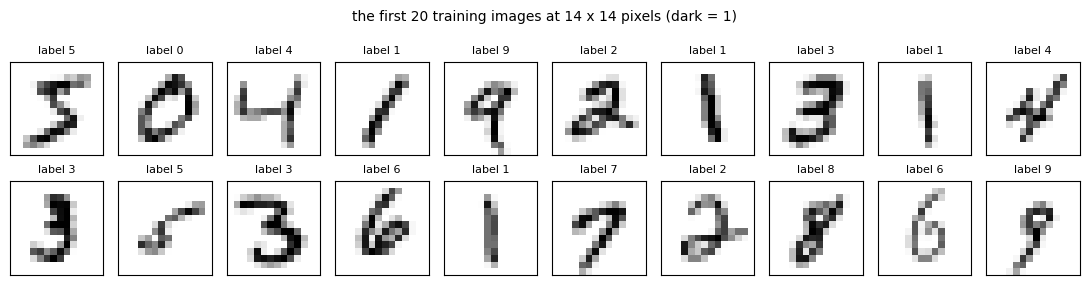

In [4]:
# ==============================================================================
# STEP 1: load the 14x14 MNIST subset (stored in the repository, no download)
# ==============================================================================
MNIST = np.load("../data/mnist_14x14.npz")
print(str(MNIST["info"]))
print()

N_SITES = 196                                     # pixels = sites of the chain
N_LABELS = 10
X_TRAIN = jnp.asarray(MNIST["x_train"].reshape(-1, N_SITES) / 255.0, dtype=RDTYPE)   # (20000, 196), row by row
Y_TRAIN = jnp.asarray(MNIST["y_train"].astype(np.int32))
X_TEST = jnp.asarray(MNIST["x_test"].reshape(-1, N_SITES) / 255.0, dtype=RDTYPE)     # (10000, 196)
Y_TEST = jnp.asarray(MNIST["y_test"].astype(np.int32))

print(f"training images {X_TRAIN.shape[0]}, test images {X_TEST.shape[0]}, pixels per image {N_SITES}")
print("training images per label:", np.bincount(np.asarray(Y_TRAIN)))
xt = np.asarray(X_TRAIN)
print(f"fraction of pixels exactly 0: {np.mean(xt == 0):.3f},  exactly 1: {np.mean(xt == 1):.4f},  "
      f"grey (0 < x < 1): {np.mean((xt > 0) & (xt < 1)):.3f}")

fig, axes = plt.subplots(2, 10, figsize=(11, 3.0))
for k, ax in enumerate(axes.flat):
    ax.imshow(xt[k].reshape(14, 14), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"label {int(Y_TRAIN[k])}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("the first 20 training images at 14 x 14 pixels (dark = 1)", fontsize=10)
fig.tight_layout()
plt.show()

The ten labels are roughly equally frequent, so random guessing scores $10\,\%$. Three quarters of all pixels are
exactly zero (background), almost none is exactly one, and a quarter is grey: the averaging over $2\times2$ blocks
turns the edges of the strokes into intermediate values. Grey pixels will matter in Section 7.3.

In [5]:
section_timer("4 feature maps")

## 4. Images as product states

### 4.1 The local feature map

The local feature map of [[1]](#ref-1), Eq. (3), turns a pixel value into a unit vector in $\mathbb R^2$,

$$\phi(x)=\begin{pmatrix}\cos\frac{\pi x}{2}\\ \sin\frac{\pi x}{2}\end{pmatrix},\qquad
\phi(0)=\begin{pmatrix}1\\0\end{pmatrix},\quad\phi(1)=\begin{pmatrix}0\\1\end{pmatrix}. \tag{2}$$

In the language of the course, a white pixel is the qubit state $\vert0\rangle$, a black pixel $\vert1\rangle$, and a
grey pixel the real superposition $\cos\frac{\pi x}2\vert0\rangle+\sin\frac{\pi x}2\vert1\rangle$, a point on the
great circle of the Bloch sphere in the $x$–$z$ plane. The whole image is the product state

$$\vert\Phi(\mathbf x)\rangle=\phi(x_0)\otimes\phi(x_1)\otimes\cdots\otimes\phi(x_{N-1}),\qquad
\Phi_{s_0\cdots s_{N-1}}(\mathbf x)=\phi_{s_0}(x_0)\,\phi_{s_1}(x_1)\cdots\phi_{s_{N-1}}(x_{N-1}), \tag{3}$$

with indices $s_j\in\{0,1\}$. It is normalised, $\langle\Phi(\mathbf x)\vert\Phi(\mathbf x)\rangle=\prod_j\Vert\phi(x_j)\Vert^2=1$,
and it has no entanglement: it is the most compressible state there is, an MPS of bond dimension 1.

### 4.2 The kernel of the feature map

Two images are compared through the scalar product of their feature vectors. For product states it factorises,

$$K(\mathbf x,\mathbf x')=\langle\Phi(\mathbf x)\vert\Phi(\mathbf x')\rangle=\prod_{j=0}^{N-1}\phi(x_j)\cdot\phi(x'_j)
=\prod_{j=0}^{N-1}\cos\frac{\pi(x_j-x'_j)}{2}, \tag{4}$$

where we used $\cos a\cos b+\sin a\sin b=\cos(a-b)$. This is a product of one local kernel per pixel, the kind of
kernel discussed in [[1]](#ref-1), Sec. II. Every factor is at most one, and a pixel that is white in one image and
black in the other contributes the factor $\cos\frac\pi2=0$: two images that differ in a single pixel from white to
black are exactly orthogonal. Handwritten digits differ in many pixels, so the feature vectors of different images
are almost orthogonal, even for two images of the same digit. Any linear model of Eq. (1) can still be very
expressive: on black-and-white images $f^\ell(\mathbf x)$ is a single component $W^\ell_{s_0\cdots s_{N-1}}$ of the
weight tensor, an arbitrary function of the image ([[1]](#ref-1), Sec. VIII.A). As a function of one grey pixel
$x_j$ with all others fixed, $f^\ell$ is $a\cos\frac{\pi x_j}2+b\sin\frac{\pi x_j}2$.

### 4.3 The linear feature map

The implementation of [[2]](#ref-2) uses instead the linear map $\phi(x)=(1-x,\,x)$ (its Sec. II A, which states that
the choice "is not very important"). It agrees with Eq. (2) on white and black pixels and differs on grey ones. Its
components add up to one, $\phi_0+\phi_1=1$, while those of Eq. (2) have unit length,
$\phi_0^2+\phi_1^2=1$. Section 7.3 shows that this difference decides how well training starts from a simple initial MPS,
and we will train with the linear map; the entanglement analysis of Section 9 uses Eq. (2), as [[3]](#ref-3) does.

The cell implements both maps and checks Eq. (4) against the scalar product of the explicit $2^{12}$-component product
states of a $3\times4$ patch of pixels.

In [6]:
# ==============================================================================
# STEP 2: local feature maps and the product-state kernel
# ==============================================================================
def feature_cos_sin(x):
    """Local feature map of Eq. (2), applied to every pixel:  x (..., N) -> phi (..., N, 2).

    MATH   phi(x) = (cos(pi x / 2), sin(pi x / 2)),   |phi| = 1
    """
    return jnp.stack([jnp.cos(jnp.pi * x / 2), jnp.sin(jnp.pi * x / 2)], axis=-1)


def feature_linear(x):
    """Linear local feature map:  x (..., N) -> phi (..., N, 2).

    MATH   phi(x) = (1 - x, x),   phi_0 + phi_1 = 1
    """
    return jnp.stack([1.0 - x, x], axis=-1)


def kernel_product(phi_a, phi_b):
    """Eq. (4): <Phi(a)|Phi(b)> = prod_j phi(a_j) . phi(b_j)  for product states given by local vectors (N, 2)."""
    return jnp.prod(jnp.sum(phi_a * phi_b, axis=-1))


def dense_product_state(phi):
    """Explicit 2^N vector of the product state phi_0 (x) ... (x) phi_{N-1} (validation only, small N)."""
    psi = phi[0]
    for p in phi[1:]:
        psi = jnp.kron(psi, p)
    return psi


# CHECKPOINT: norms and the two pure pixel values
phi_cs, phi_lin = feature_cos_sin(X_TRAIN[:500]), feature_linear(X_TRAIN[:500])
err_norm = max_abs(jnp.sum(phi_cs ** 2, -1) - 1.0)
err_sum = max_abs(jnp.sum(phi_lin, -1) - 1.0)
err_ends = max_abs(feature_cos_sin(jnp.array([0.0, 1.0])) - jnp.eye(2)) + max_abs(feature_linear(jnp.array([0.0, 1.0])) - jnp.eye(2))
print(f"max | |phi_cs|^2 - 1 | = {err_norm:.1e},   max | phi_lin_0 + phi_lin_1 - 1 | = {err_sum:.1e},   "
      f"error at x = 0, 1: {err_ends:.1e}")
assert err_norm < TOL and err_sum < TOL and err_ends < TOL

# CHECKPOINT: Eq. (4) against explicit 2^12-component vectors of a 3 x 4 patch from the middle of two images
patch = np.array([14 * r + q for r in range(5, 8) for q in range(5, 9)])   # rows 5-7, columns 5-8
pa, pb = feature_cos_sin(X_TRAIN[0, patch]), feature_cos_sin(X_TRAIN[7, patch])
k_dense = float(jnp.dot(dense_product_state(pa), dense_product_state(pb)))
k_formula = float(jnp.prod(jnp.cos(jnp.pi * (X_TRAIN[0, patch] - X_TRAIN[7, patch]) / 2)))
print(f"3x4 patch: <Phi|Phi'> explicit = {k_dense:.12f},  Eq. (4) = {k_formula:.12f}")
assert abs(k_dense - k_formula) < TOL and abs(float(kernel_product(pa, pb)) - k_formula) < TOL

# the kernel matrix of the first eight training images, whole images
K8 = np.array([[float(kernel_product(phi_cs[a], phi_cs[b])) for b in range(8)] for a in range(8)])
print("\nlabels of the first eight training images:", np.asarray(Y_TRAIN[:8]))
print("kernel K(x, x') of Eq. (4) between them:")
with np.printoptions(precision=1, suppress=False, linewidth=120):
    print(K8)

max | |phi_cs|^2 - 1 | = 2.2e-16,   max | phi_lin_0 + phi_lin_1 - 1 | = 0.0e+00,   error at x = 0, 1: 6.1e-17


3x4 patch: <Phi|Phi'> explicit = 0.000078846639,  Eq. (4) = 0.000078846639



labels of the first eight training images: [5 0 4 1 9 2 1 3]
kernel K(x, x') of Eq. (4) between them:
[[1.0e+00 3.7e-15 2.1e-22 1.1e-19 4.9e-19 1.5e-18 1.4e-18 6.5e-13]
 [3.7e-15 1.0e+00 3.8e-25 2.2e-25 2.2e-21 3.0e-21 1.9e-29 4.0e-22]
 [2.1e-22 3.8e-25 1.0e+00 9.9e-20 3.1e-18 6.7e-18 5.3e-20 1.4e-21]
 [1.1e-19 2.2e-25 9.9e-20 1.0e+00 8.7e-17 7.3e-18 4.1e-19 5.5e-20]
 [4.9e-19 2.2e-21 3.1e-18 8.7e-17 1.0e+00 2.9e-14 1.9e-13 1.1e-17]
 [1.5e-18 3.0e-21 6.7e-18 7.3e-18 2.9e-14 1.0e+00 2.8e-23 3.7e-14]
 [1.4e-18 1.9e-29 5.3e-20 4.1e-19 1.9e-13 2.8e-23 1.0e+00 6.0e-26]
 [6.5e-13 4.0e-22 1.4e-21 5.5e-20 1.1e-17 3.7e-14 6.0e-26 1.0e+00]]


Both maps are normalised as stated, and the factorised kernel agrees with the explicit scalar product of two
$4096$-component vectors. The kernel matrix of eight whole images has ones on the diagonal and off-diagonal entries
that are zero or tiny, even between the two images of the digit 1 (positions 3 and 6, counted from 0): different
images are nearly orthogonal states of 196 qubits, as argued above. A linear model on such states has to learn a
weight tensor that overlaps with many nearly orthogonal states of the same class.

In [7]:
section_timer("5 MPS classifier")

## 5. The MPS classifier

### 5.1 The weight tensor as a matrix product state

The label index $\ell$ is one more index of the weight tensor, $W^\ell_{s_0\cdots s_{N-1}}$, an order-$(N+1)$ tensor
([[1]](#ref-1), Sec. III). Its MPS form ([[1]](#ref-1), Eq. (5), written here with sites counted from 0) is

$$W^\ell_{s_0\cdots s_{N-1}}=\sum_{a_1,\dots,a_{N-1}}A^{[0]s_0}_{a_1}A^{[1]s_1}_{a_1a_2}\cdots A^{[c]\,\ell s_c}_{a_ca_{c+1}}
\cdots A^{[N-1]s_{N-1}}_{a_{N-1}}, \tag{5}$$

the chain of rank-3 tensors of a matrix product state, except that one tensor, at the *label site* $c$, carries
the extra label leg. The bond index $a_j$ connects sites $j-1$ and $j$ and runs over $\chi$ values (the bond
dimension, called $m$ in [[1]](#ref-1)). Figure 1
shows the diagrams. The MPS holds $(N-1)\cdot2\chi^2+2\chi^2\cdot10$ numbers, about $2N\chi^2$: for $N=196$ and $\chi=16$,
$1.05\times10^5$ numbers instead of $10\times2^{196}$.

![Three tensor diagrams: (a) the weight tensor W with one leg per pixel and a label leg; (b) the same as a matrix product state with the label leg on site c; (c) the decision function, the MPS with every pixel leg closed by a feature vector](figures/mps_classifier.svg)\
**Figure 1.** (a) The weight tensor of Eq. (1) has a leg per pixel and a label leg. (b) Its matrix product form,
Eq. (5); the horizontal legs have dimension $\chi$, the label leg sits on site $c$. (c) The decision function
$f^\ell(\mathbf x)$: every pixel leg of the MPS is closed with the local feature vector of the image.

### 5.2 Contracting the classifier with an image

Inserting the product state (3) into Eq. (1) and the MPS (5), each physical index $s_j$ is summed with
$\phi_{s_j}(x_j)$ alone, so every site becomes a $\chi\times\chi$ matrix that depends on one pixel,

$$M^{[j]}(x_j)=\sum_{s=0}^{1}\phi_s(x_j)\,A^{[j]s},\qquad
f^\ell(\mathbf x)=M^{[0]}(x_0)\cdots M^{[c-1]}(x_{c-1})\,\Big(\sum_s\phi_s(x_c)A^{[c]\ell s}\Big)\,M^{[c+1]}(x_{c+1})\cdots M^{[N-1]}(x_{N-1}). \tag{6}$$

The first and last factors are a row and a column vector. We store all tensors with full shape $(\chi,2,\chi)$ and
select the boundary rows and columns with the unit vector $e_0=(1,0,\dots,0)$, so the chain starts with the row
vector $e_0^{\rm T}M^{[0]}$ and ends with $M^{[N-1]}e_0$. Multiplying a vector by the matrices one after the other costs
$O(\chi^2)$ per site, so the whole classifier costs $O(N\chi^2)$ per image instead of $O(2^N)$. The label is
predicted as the largest score: $\hat\ell(\mathbf x)=\arg\max_\ell f^\ell(\mathbf x)$, the natural rule for the
cross-entropy training below; [[1]](#ref-1) uses the largest $\vert f^\ell\vert$, natural for its quadratic cost with
targets $0$ and $1$.

In code the site tensors other than the label site form one array `A` of shape $(N-1,\chi,2,\chi)$ and the label
tensor is `lab` of shape $(\chi,2,10,\chi)$, at site $c=N/2=98$ (row 7, column 0 of the image), in the middle of
the chain as in [[2]](#ref-2). The einsum
`"jasb,js->jab"` forms all matrices $M^{[j]}$ of an image at once; two `lax.scan`s then run from the left end to
the label site and from the right end to the label site, and the two vectors meet the label tensor in the einsum
`"a,s,aslb,b->l"`. The scans hold one vector of length $\chi$, whatever the length of the chain, and compile one
body for all sites.

### 5.3 Long products: rescaling and the logarithm of the norm

A product of 98 matrices can grow or shrink exponentially. If the typical factor multiplies a vector's norm by
$g$, the result is of order $g^{98}$; already $g=3$ gives $10^{47}$, beyond the largest single-precision number
$3.4\times10^{38}$. The scan therefore divides the vector by its norm after every site and adds the logarithm of that
norm to a running sum $\log Z$; the score is $f^\ell=\hat f^\ell\,e^{\log Z}$ with $\hat f^\ell$ of order one. The
rescaling is exact: it only moves a positive factor out of the product. The cell checks the contraction against the full
weight tensor $W^\ell_{s_0\cdots s_7}$, built explicitly for a chain of $N=8$ sites, and then shows what the rescaling
prevents.

In [8]:
# ==============================================================================
# STEP 3: the MPS classifier, its contraction with an image, and a brute-force check
# ==============================================================================
def init_mps_params(key, N, chi, sigma=1e-2):
    """MPS classifier with label site c = N // 2:  A (N-1, chi, 2, chi) for the other sites, lab (chi, 2, 10, chi).

    MATH            A^{[j] s} = 1 + sigma * noise  for s = 0, 1  (identity matrices plus small Gaussian noise),
                    A^{[c] l s} = 1 + sigma * noise for every label l
    WHY             With phi_0 + phi_1 = 1 (linear map), M^{[j]} = 1 + O(sigma) for every image, so f = O(1) at the start
                    (Section 7.3).  The noise breaks the symmetry between labels and between bond directions.
    """
    k1, k2 = jax.random.split(key)
    eye2 = jnp.stack([jnp.eye(chi, dtype=RDTYPE)] * 2, axis=1)                   # (chi, 2, chi)
    A = eye2[None] + sigma * jax.random.normal(k1, (N - 1, chi, 2, chi), RDTYPE)
    lab = jnp.einsum("asb,l->aslb", eye2, jnp.ones(N_LABELS, RDTYPE)) + sigma * jax.random.normal(
        k2, (chi, 2, N_LABELS, chi), RDTYPE)
    return {"A": A, "lab": lab}


def _scan_vector_through(v, Ms):
    """v^T Ms[0] Ms[1] ...  with the vector renormalised after every factor.

    MATH            v <- v M / |v M|,   logZ <- logZ + log |v M|    =>   v_true = exp(logZ) * v
    JAX             lax.scan: one compiled body, carried state (v, logZ) of size chi + 1
    """
    def body(carry, M):
        v, lz = carry
        v = v @ M
        nv = jnp.linalg.norm(v)
        return (v / nv, lz + jnp.log(nv)), None
    (v, lz), _ = lax.scan(body, (v, jnp.zeros((), RDTYPE)), Ms)
    return v, lz


def mps_scores_parts(params, phi):
    """Scores of one image, Eq. (6), as (f_hat (10,), logZ) with f = f_hat * exp(logZ).

    MATH            f^l = e0^T M_0 ... M_{c-1} (sum_s phi_s(x_c) A_c^{l s}) M_{c+1} ... M_{N-1} e0,  M_j = sum_s phi_s(x_j) A_j^s
    IMPLEMENTATION  left vector by a scan over sites 0..c-1; right vector by a scan over the transposed matrices of
                    sites N-1..c+1; both renormalised per site (Section 5.3)
    COST            O(N chi^2) per image
    """
    A, lab = params["A"], params["lab"]
    N, chi = phi.shape[0], A.shape[1]
    c = N // 2
    M = jnp.einsum("jasb,js->jab", A, jnp.concatenate([phi[:c], phi[c + 1:]]))      # (N-1, chi, chi)
    e0 = jnp.zeros(chi, RDTYPE).at[0].set(1.0)
    vl, zl = _scan_vector_through(e0, M[:c])
    vr, zr = _scan_vector_through(e0, jnp.swapaxes(M[c:], 1, 2)[::-1])
    return jnp.einsum("a,s,aslb,b->l", vl, phi[c], lab, vr), zl + zr


def mps_scores(params, phi):
    """f^l(x) for one image (phi of shape (N, 2)), Eq. (6)."""
    f_hat, lz = mps_scores_parts(params, phi)
    return f_hat * jnp.exp(lz)


def dense_weight_tensor(params, N):
    """Contract the MPS (5) into the full tensor W[s_0, ..., s_{N-1}, l] (validation only, 10 * 2^N numbers)."""
    A, lab = params["A"], params["lab"]
    c = N // 2
    T = A[0][0]                                                     # (2, chi): left boundary row e0
    for j in range(1, N):
        if j == c:
            T = jnp.einsum("...a,aslb->...slb", T, lab)            # label leg appears and is carried along
        else:
            Aj = A[j] if j < c else A[j - 1]
            T = jnp.einsum("...a,asb->...sb", T, Aj)
    return T[..., 0]                                                # right boundary column e0; axes s_0..s_c, l, s_{c+1}..s_{N-1}


# CHECKPOINT: Eq. (6) against the full weight tensor of an N = 8 chain (label leg on site 4)
N_small, chi_small = 8, 3
p_small = init_mps_params(jax.random.PRNGKey(0), N_small, chi_small, sigma=0.5)
T = dense_weight_tensor(p_small, N_small)                         # axes: s_0 .. s_c (c = 4), l, s_5 .. s_7
W_dense = jnp.moveaxis(T, N_small // 2 + 1, -1).reshape(2 ** N_small, N_LABELS)       # (2^N, 10)
x_small = jax.random.uniform(jax.random.PRNGKey(1), (6, N_small), RDTYPE)
phi_small = feature_linear(x_small)
f_dense = jnp.stack([dense_product_state(p) for p in phi_small]) @ W_dense           # f = Phi(x) . W
f_mps = jax.vmap(mps_scores, (None, 0))(p_small, phi_small)
err_contr = max_abs(f_mps - f_dense) / max_abs(f_dense)
print(f"N = 8, chi = 3: max |f_MPS - f_dense| / max |f| = {err_contr:.1e}   "
      f"(full tensor: {W_dense.size} numbers, MPS: {p_small['A'].size + p_small['lab'].size})")
assert err_contr < TOL

# what the rescaling prevents: a random Gaussian MPS of the full size
p_rand = {"A": jax.random.normal(jax.random.PRNGKey(2), (N_SITES - 1, 8, 2, 8), RDTYPE),
          "lab": jax.random.normal(jax.random.PRNGKey(3), (8, 2, N_LABELS, 8), RDTYPE)}
fh_rand, lz_rand = jax.vmap(mps_scores_parts, (None, 0))(p_rand, feature_linear(X_TRAIN[:200]))
log10_f = np.log10(np.max(np.abs(np.asarray(fh_rand)), axis=1)) + np.asarray(lz_rand) / np.log(10)   # log10 max_l |f^l|
print(f"\nrandom Gaussian MPS, chi = 8: log10 max_l |f^l| over 200 images from {log10_f.min():.0f} to {log10_f.max():.0f}")
v32 = jnp.zeros(8, jnp.float32).at[0].set(1.0)                 # the same product without rescaling, in float32
M32 = jnp.einsum("jasb,js->jab", p_rand["A"], feature_linear(X_TRAIN[0])[:-1]).astype(jnp.float32)
for j in range(N_SITES // 2):
    v32 = v32 @ M32[j]
print(f"left half of image 0 without rescaling, float32: |v| = {float(jnp.linalg.norm(v32))}")

N = 8, chi = 3: max |f_MPS - f_dense| / max |f| = 1.1e-15   (full tensor: 2560 numbers, MPS: 306)



random Gaussian MPS, chi = 8: log10 max_l |f^l| over 200 images from 74 to 81


left half of image 0 without rescaling, float32: |v| = inf


The contraction of Eq. (6) reproduces the scores of the full weight tensor ($2560$ numbers) to round-off. For a random
Gaussian MPS the scores are between $10^{74}$ and $10^{81}$: the logarithm of the norm is perfectly well defined, but
the number itself overflows in single precision (the last line prints `inf`). Since $\log\vert f\vert$ grows linearly
with the number of sites, the same kind of tensors on $28\times28$ images (784 sites) would give scores near
$10^{300}$, at the double-precision limit $1.8\times10^{308}$. With per-site rescaling the intermediate products never
overflow; the score is formed as $\hat f^\ell e^{\log Z}$ only at the end, and a cost that works with $\log Z$ directly
would avoid even that. The initial MPS of `init_mps_params`, identity matrices plus small noise, avoids the problem altogether for the linear
map, as Section 7.3 shows.

In [9]:
section_timer("6 DMRG sweeps")

## 6. Training I: the sweeping algorithm, DMRG for a classification cost

The sweeping algorithm of [[1]](#ref-1), Sec. V, is the two-site DMRG algorithm derived in
[notebook 18, matrix product states](../ch07_tensor_networks/18_mps_tebd.ipynb), Section 6 (DMRG was introduced in [[5]](#ref-5)), with the energy replaced by a cost function summed over the training images.
Figure 2 shows one step.

![Three diagrams: (a) the bond tensor B formed from sites j and j+1, carrying the label leg; (b) the projected input of one image: left environment, two feature vectors, right environment; (c) the SVD split of B into U, S, V-dagger with chi kept values, and the label leg moving to site j+1](figures/mps_sweep_step.svg)\
**Figure 2.** One step of the sweep. (a) The tensors of sites $j$ and $j+1$ are merged into the bond tensor $B^\ell$,
which carries the label leg. (b) Each training image enters through its projected input $\tilde\Phi_n$: the left and
right environments $L_n$ and $R_n$ (the image contracted with all other tensors) and the two feature vectors.
(c) After the update, an SVD splits $B^\ell$ back into two tensors, keeping $\chi$ singular values; moving to the
right, the label leg goes with $SV^\dagger$ to site $j+1$.

### 6.1 The dictionary between DMRG and the sweep

| DMRG for a ground state | sweeping training of the classifier ([[1]](#ref-1), Sec. V) |
|---|---|
| two-site tensor $\theta$ of sites $j,j+1$ | bond tensor $B^\ell$ of sites $j,j+1$, with the label leg |
| left and right environments $L_j$, $R_j$ of the Hamiltonian (MPO) | left and right environments $L_n$, $R_n$ of every training image $n$ |
| energy $\langle\theta\vert H_{\rm eff}\vert\theta\rangle$ | cost $C(B)$ summed over the training images |
| local eigenproblem $H_{\rm eff}\theta=E\theta$, solved by Lanczos | a few gradient steps on $C(B)$ |
| SVD split of $\theta$, keep $\chi$ values, move the orthogonality centre | SVD split of $B^\ell$, keep $\chi$ values, move the label leg with the centre |
| environments updated by one site per step | environments of the images updated by one site per step |
| sweeps left → right → left until the energy converges | sweeps until the cost converges |

Three things differ. The quantity to minimise is a sum of $N_{\rm T}$ terms, one per training image, so the
environments are $N_{\rm T}$ vectors of length $\chi$ per bond, where DMRG has one MPO environment. The local problem is
not an eigenproblem, and a full minimisation of the local cost is not even desirable, because the truncation that
follows can undo much of it (Section 6.3). And the label index rides on the orthogonality centre: whichever tensor
carries the centre also carries $\ell$.

### 6.2 The bond tensor and the projected inputs

Let $N_{\rm T}$ be the number of training images, $n=0,\dots,N_{\rm T}-1$ their index, $x_{n,j}$ pixel $j$ of image
$n$ and $y_n$ its label. Moving right, the label sits on site $j$, and the tensors of sites $j$ and $j+1$ are merged
into the bond tensor $B^\ell_{a s t b}=\sum_mA^{[j]\ell s}_{am}A^{[j+1]t}_{mb}$ (einsum `"aslm,mtb->astlb"`); moving left,
the label sits on site $j+1$ and $B^\ell_{astb}=\sum_mA^{[j]s}_{am}A^{[j+1]\ell t}_{mb}$ (einsum `"asm,mtlb->astlb"`).
With all other tensors fixed, the score of image $n$ is linear in $B$ ([[1]](#ref-1), Eq. (7)):

$$f^\ell_n=\sum_{a,s,t,b}B^\ell_{astb}\,\tilde\Phi_{n,astb},\qquad
\tilde\Phi_{n,astb}=L_{n,a}\,\phi_s(x_{n,j})\,\phi_t(x_{n,j+1})\,R_{n,b}. \tag{7}$$

Here $L_n$ is image $n$ contracted with all tensors left of site $j$ (a vector of length $\chi$) and $R_n$ with all
tensors right of site $j+1$: the environments of the data, or *projected inputs* of [[1]](#ref-1), Fig. 6. Collecting
the $4\chi^2$ numbers $\tilde\Phi_{n,astb}$ of all images as the rows of a matrix $\tilde\Phi$ of shape
$(N_{\rm T},4\chi^2)$ and the bond tensor as a matrix $\mathbf B$ of shape $(4\chi^2,10)$, all scores are one matrix
product, $F=\tilde\Phi\mathbf B$, with $F_{n\ell}=f^\ell_n$.

### 6.3 The local cost and the gradient step

[[1]](#ref-1) minimises the quadratic cost $\frac12\sum_n\sum_\ell(f^\ell_n-\delta_{\ell,y_n})^2$ (its Eq. (6)). We use
the cross-entropy of [[2]](#ref-2) (its Eq. (3)). It turns the ten scores of an image into probabilities with the
softmax function; scores used in this way are called *logits*. The cost is the mean of $-\log$ of the probability
given to the correct label:

$$C(B)=-\frac1{N_{\rm T}}\sum_{n}\log p_n(y_n),\qquad p_n(\ell)=\frac{e^{f^\ell_n}}{\sum_{k}e^{f^k_n}},\qquad
\frac{\partial C}{\partial\mathbf B}=\frac1{N_{\rm T}}\tilde\Phi^{\rm T}\big(\Pi-Y\big), \tag{8}$$

where $\Pi_{n\ell}=p_n(\ell)$ and $Y_{n\ell}=\delta_{\ell,y_n}$; the gradient follows from
$\partial\log p_n(y)/\partial f^\ell_n=\delta_{\ell y}-p_n(\ell)$ and $\partial f^\ell_n/\partial\mathbf B_{k\ell}=\tilde\Phi_{nk}$.
$C(B)$ is the cross-entropy of the whole classifier over all training images, evaluated with the current tensors; it
is local only in the sense that only $B$ is varied. With automatic differentiation, Section 7.3 finds that the
quadratic cost trains much more slowly than the cross-entropy at our budget. The update is
$\mathbf B\leftarrow\mathbf B-\alpha\,\partial C/\partial\mathbf B$, the gradient step of [[1]](#ref-1), Fig. 7(a),
repeated a few times.

The step size follows from the curvature. The Hessian of $-\log p_n(y_n)$ in the logits of one image is
$H_n=\mathrm{diag}(p)-pp^{\rm T}$. Its row $\ell$ has the diagonal element $p_\ell(1-p_\ell)$ and off-diagonal elements of
total magnitude $p_\ell\sum_{k\neq\ell}p_k=p_\ell(1-p_\ell)$, so by the Gershgorin circle theorem every eigenvalue is at
most $\max_\ell2p_\ell(1-p_\ell)\leq\frac12$. Since $f_n=\mathbf B^{\rm T}\tilde\Phi_n$, the Hessian of $C$ in $\mathbf B$
is $\frac1{N_{\rm T}}\sum_n\tilde\Phi_n\tilde\Phi_n^{\rm T}\otimes H_n$, which is bounded by
$\frac1{2N_{\rm T}}\tilde\Phi^{\rm T}\tilde\Phi\otimes\mathbb 1$. The curvature is therefore at most
$\Lambda=\lambda_{\max}(\tilde\Phi^{\rm T}\tilde\Phi)/(2N_{\rm T})$, and a gradient step with $\alpha=1/\Lambda$ does not
increase the cost (any step below $2/\Lambda$ would do). $\lambda_{\max}(\tilde\Phi^{\rm T}\tilde\Phi)$ is estimated by
20 steps of power iteration, $v\leftarrow\tilde\Phi^{\rm T}\tilde\Phi v/\Vert\tilde\Phi^{\rm T}\tilde\Phi v\Vert$, which
needs only products with $\tilde\Phi$ and $\tilde\Phi^{\rm T}$; the estimate is slightly below the true value, well
within the factor 2 of margin.

Fitting $B$ exactly is not the aim. A minimiser of the local cost, when it exists, or any point far along the descent
path, has in general rank up to $2\chi$ in the split of Section 6.4, and its truncation to $\chi$ is chosen by the
Frobenius norm of $B$, without regard to the cost, so it can undo much of the fit (Exercise 2 tests this). A few steps
from the current $B$, which has rank $\chi$, change it only slightly, and the truncation then discards little
(Section 6.7 measures the discarded weight). This matches the "small update" of [[1]](#ref-1), Sec. V.

### 6.4 The SVD split and the moving label

After the update the bond tensor is split by a singular value decomposition, as in two-site DMRG. Moving
right, the rows of the matrix are $(a,s)$ and the columns $(t,\ell,b)$ ([[1]](#ref-1), Eq. (11)):

$$B_{(as),(t\ell b)}=\sum_kU_{(as),k}\,S_k\,V^\dagger_{k,(t\ell b)},\qquad A^{[j]}=\text{first }\chi\text{ columns of }U,\qquad
A^{[j+1]\ell}=\text{first }\chi\text{ rows of }SV^\dagger. \tag{9}$$

$A^{[j]}$ is left-canonical, $\sum_sA^{[j]s\dagger}A^{[j]s}=1$, and the label leg has moved to site $j+1$ together with
the orthogonality centre. Moving left, the rows are $(a,s,\ell)$ and the columns $(t,b)$, $A^{[j+1]}=V^\dagger$ is
right-canonical and $US$ carries the label to site $j$. Keeping the $\chi$ largest singular values is the best rank-$\chi$
approximation in the Frobenius norm (Eckart–Young theorem [[6]](#ref-6)), and the squared
relative error in that norm is the discarded weight $\varepsilon=\sum_{k\geq\chi}S_k^2/\sum_kS_k^2$ (singular
values counted from $k=0$).

### 6.5 Environments: cached, advanced by one site, and rescaled

Recomputing $L_n$ and $R_n$ from the ends of the chain at every bond would cost $O(N)$ per step and $O(N^2)$ per
sweep. As in DMRG they are cached and advanced by one site ([[1]](#ref-1), Fig. 7(c)): after the split at bond $j$
moving right,

$$L^{(j+1)}_{n,b}=\sum_{a,s}L^{(j)}_{n,a}\,\phi_s(x_{n,j})\,A^{[j]s}_{ab}\qquad(\text{einsum }\texttt{"na,ns,asb->nb"}), \tag{10}$$

and symmetrically $R^{(j)}_{n,a}=\sum_{t,b}A^{[j]t}_{ab}\,\phi_t(x_{n,j})\,R^{(j+1)}_{n,b}$ moving left. The
environments are stored as stacked arrays `Lst` of shape $(N,N_{\rm T},\chi)$ and `Rst` of shape $(N+1,N_{\rm T},\chi)$;
entry $j$ of `Lst` belongs to the sites left of $j$, entry $j$ of `Rst` to the sites from $j$ on.

The norm of an environment cannot grow along the chain. A left-canonical tensor is an isometry: the map
$(L,\phi)\mapsto\sum_{a,s}L_a\phi_sA^{[j]s}_{ab}$ is the vector $L\otimes\phi$ multiplied by a matrix with orthonormal
columns, so its norm is at most $\Vert L\Vert\,\Vert\phi\Vert$, and $\Vert\phi\Vert\leq1$ for both feature maps. For the
initial tensors of the next cell, $A^0=A^1\approx\frac1{\sqrt2}\mathbb 1$ and $\phi_0+\phi_1=1$, the factor is
$\frac1{\sqrt2}$ for every image, and the right environment of the first bond, after 194 sites, is of order
$2^{-97}\approx6\times10^{-30}$. The scores (7) would then need a bond tensor of order $10^{29}$. We avoid this with a
gauge transformation: after each split the new environment is divided by its root-mean-square norm $\kappa$ over the
images, the new canonical tensor by $\kappa$, and the tensor that carries the centre is multiplied by $\kappa$. The
product of the two tensors, and therefore the model, is unchanged. The rescaled tensor is canonical up to the factor
$\kappa^{-2}$ in $\sum_sA^{s\dagger}A^s$, which changes no singular vector and no step of the algorithm.

### 6.6 From formula to code

The sweep stores the MPS differently from the classifier of Section 5, because its label must move. All $N$ sites
have an entry in the array `As` of shape $(N,\chi,2,\chi)$, and the tensor that carries the centre and the label leg is
kept separately as `C`, of shape $(\chi,2,10,\chi)$; the entry of `As` at the centre's site is not used until the
centre moves on and the split writes it. The end bonds are handled as in Section 5, with the boundary index fixed to

0. The rows $a\neq0$ of the site-0 tensor and the columns $b\neq0$ of the site-$(N-1)$ tensor therefore never meet an
image: they receive no gradient and never enter a score. They are not zero, however: they take part in the SVDs of
the end bonds and in their discarded weight, and each split of an end bond rewrites them. Exercise 9 sets these entries to zero, as a boundary bond of
dimension 1 would, and compares the training.

A whole half sweep is one `lax.scan` over the bond index $j$: the carry holds the site tensors, the centre tensor and
one of the two environment stacks, and each step reads and writes them with `.at[j].set(...)`, which XLA can perform
in place inside a compiled scan. The checkpoints test the pieces against independent references on a chain of $N=8$
sites:

1. the gradient of Eq. (8) against `jax.grad` of the cross-entropy computed from the full weight tensor, with the
   bond tensor inserted;
2. the curvature bound $\lambda_{\max}(\mathrm{diag}(p)-pp^{\rm T})\leq\frac12$;
3. the truncated SVD against the full one: the split with $\chi$ at least the rank reproduces $B$ exactly, the
   truncation error equals the discarded weight, and $A^{[j]}$ is left-canonical.

In [10]:
# ==============================================================================
# STEP 4: the pieces of the sweep, Eqs. (7)-(10)
# ==============================================================================
def left_env_step(L, A, phi_j):
    """Eq. (10): L'[n, b] = sum_{a,s} L[n, a] phi_j[n, s] A[a, s, b]."""
    return jnp.einsum("na,ns,asb->nb", L, phi_j, A)


def right_env_step(R, A, phi_j):
    """R'[n, a] = sum_{s,b} A[a, s, b] phi_j[n, s] R[n, b]."""
    return jnp.einsum("asb,ns,nb->na", A, phi_j, R)


def projected_inputs(L, phi_j, phi_k, R):
    """Eq. (7): Phit[n, (a s t b)] = L[n, a] phi_j[n, s] phi_k[n, t] R[n, b],  shape (N_T, 4 chi^2)."""
    return jnp.einsum("na,ns,nt,nb->nastb", L, phi_j, phi_k, R).reshape(L.shape[0], -1)


def bond_to_matrix(Bt):
    """Bond tensor B[a, s, t, l, b] -> its matrix form Bm[(a s t b), l] (the bold B of Eq. (8))."""
    return jnp.transpose(Bt, (0, 1, 2, 4, 3)).reshape(-1, Bt.shape[3])


def matrix_to_bond(Bm, shape):
    a, s, t, l, b = shape
    return jnp.transpose(Bm.reshape(a, s, t, b, l), (0, 1, 2, 4, 3))


def cross_entropy(F, Y):
    """Eq. (8): C = -(1/N_T) sum_n log softmax(F_n)[y_n], F scores (N_T, 10), Y one-hot (N_T, 10)."""
    return -jnp.mean(jnp.sum(Y * jax.nn.log_softmax(F), axis=1))


def local_gradient(Bm, Phit, Y):
    """Eq. (8): dC/dBm = Phit^T (softmax(Phit Bm) - Y) / N_T."""
    return Phit.T @ (jax.nn.softmax(Phit @ Bm) - Y) / Phit.shape[0]


def local_update(Bt, Phit, Y, n_steps, n_power=20):
    """A few gradient steps on the bond tensor with step 1/Lambda, Lambda = lambda_max(Phit^T Phit) / (2 N_T).

    MATH            Bm <- Bm - (1/Lambda) Phit^T (softmax(Phit Bm) - Y) / N_T,   repeated n_steps times
    IMPLEMENTATION  lambda_max by power iteration v <- Phit^T Phit v / |Phit^T Phit v| (n_power steps, starting from
                    the column sums of Phit); both loops are lax.scans
    RETURNS         updated bond tensor, cost after the steps
    """
    Bm = bond_to_matrix(Bt)
    v0 = jnp.sum(Phit, axis=0)

    def power(v, _):
        w = Phit.T @ (Phit @ v)
        return w / jnp.linalg.norm(w), None
    v, _ = lax.scan(power, v0 / jnp.linalg.norm(v0), None, length=n_power)
    Lam = 0.5 * (v @ (Phit.T @ (Phit @ v))) / Phit.shape[0]

    def step(Bm, _):
        return Bm - local_gradient(Bm, Phit, Y) / Lam, None
    Bm, _ = lax.scan(step, Bm, None, length=n_steps)
    return matrix_to_bond(Bm, Bt.shape), cross_entropy(Phit @ Bm, Y)


def split_moving_right(Bt, chi):
    """Eq. (9): B[(a s), (t l b)] = U S V^dag;  A_j = U[:, :chi] (left-canonical), centre (S V^dag)[:chi] -> site j+1.

    RETURNS  A_j (chi, 2, chi), new centre (chi, 2, 10, chi), discarded weight eps = sum_{k>=chi} S_k^2 / sum_k S_k^2
    """
    a, s, t, l, b = Bt.shape
    U, S, Vh = jnp.linalg.svd(Bt.reshape(a * s, t * l * b), full_matrices=False)
    eps = jnp.sum(S[chi:] ** 2) / jnp.sum(S ** 2)
    return U[:, :chi].reshape(a, s, chi), (S[:chi, None] * Vh[:chi]).reshape(chi, t, l, b), eps


def split_moving_left(Bt, chi):
    """B[(a s l), (t b)] = U S V^dag;  centre (U S)[:, :chi] stays on site j,  A_{j+1} = V^dag[:chi] (right-canonical)."""
    a, s, t, l, b = Bt.shape
    U, S, Vh = jnp.linalg.svd(jnp.transpose(Bt, (0, 1, 3, 2, 4)).reshape(a * s * l, t * b), full_matrices=False)
    eps = jnp.sum(S[chi:] ** 2) / jnp.sum(S ** 2)
    return (U[:, :chi] * S[None, :chi]).reshape(a, s, l, chi), Vh[:chi].reshape(chi, t, b), eps


# ------------------------------------------------------------------------------
# CHECKPOINT 1: the gradient of Eq. (8) against jax.grad through the full weight tensor (N = 8, chi = 3)
# ------------------------------------------------------------------------------
def dense_scores_with_bond(As, Bt, j, phi):
    """Scores of images phi (N_T, N, 2) from the full weight tensor of the chain As with sites j, j+1 replaced by Bt."""
    N = As.shape[0]
    T = As[0][0] if j > 0 else Bt[0]                                       # left boundary row e0
    k = 1 if j > 0 else 2
    while k < N:
        if k == j:
            T = jnp.einsum("...a,astlb->...stlb", T, Bt)
            k += 2
        else:
            T = jnp.einsum("...a,asb->...sb", T, As[k])
            k += 1
    T = T[..., 0]                                                         # right boundary column e0
    W_full = jnp.moveaxis(T, j + 2, -1).reshape(2 ** N, N_LABELS)
    return jnp.stack([dense_product_state(p) for p in phi]) @ W_full


kA, kB, kx, ky = jax.random.split(jax.random.PRNGKey(4), 4)
As_t = jax.random.normal(kA, (N_small, chi_small, 2, chi_small), RDTYPE) / np.sqrt(2 * chi_small)
Bt_t = jax.random.normal(kB, (chi_small, 2, 2, N_LABELS, chi_small), RDTYPE)
j_t = 3
phi_t = feature_linear(jax.random.uniform(kx, (12, N_small), RDTYPE))
Y_t = jax.nn.one_hot(jax.random.randint(ky, (12,), 0, N_LABELS), N_LABELS, dtype=RDTYPE)
e0_t = jnp.zeros((12, chi_small), RDTYPE).at[:, 0].set(1.0)
L_t, R_t = e0_t, e0_t
for k in range(j_t):
    L_t = left_env_step(L_t, As_t[k], phi_t[:, k])
for k in range(N_small - 1, j_t + 1, -1):
    R_t = right_env_step(R_t, As_t[k], phi_t[:, k])
Phit_t = projected_inputs(L_t, phi_t[:, j_t], phi_t[:, j_t + 1], R_t)
g_formula = matrix_to_bond(local_gradient(bond_to_matrix(Bt_t), Phit_t, Y_t), Bt_t.shape)
g_autodiff = jax.grad(lambda B: cross_entropy(dense_scores_with_bond(As_t, B, j_t, phi_t), Y_t))(Bt_t)
err_grad = max_abs(g_formula - g_autodiff) / max_abs(g_autodiff)
err_scores = max_abs(Phit_t @ bond_to_matrix(Bt_t) - dense_scores_with_bond(As_t, Bt_t, j_t, phi_t))
print(f"Eq. (7): max |Phit Bm - f_dense| = {err_scores:.1e};   Eq. (8): max |grad_formula - jax.grad| / max |grad| = {err_grad:.1e}")
assert err_scores < TOL and err_grad < TOL

# CHECKPOINT 2: curvature of the cross-entropy in the logits, lambda_max(diag(p) - p p^T) <= 1/2
p_rand10 = jax.nn.softmax(3.0 * jax.random.normal(jax.random.PRNGKey(5), (2000, N_LABELS), RDTYPE), axis=1)
lam_H = jax.vmap(lambda p: jnp.linalg.eigvalsh(jnp.diag(p) - jnp.outer(p, p))[-1])(p_rand10)
print(f"largest eigenvalue of diag(p) - p p^T over 2000 random distributions: {float(lam_H.max()):.4f} (bound 0.5)")
assert float(lam_H.max()) <= 0.5 + TOL

# CHECKPOINT 3: SVD split. chi >= rank: exact; chi < rank: error^2 = discarded weight; U left-canonical
B_exact_r = jnp.einsum("asm,mtlb->astlb", As_t[2], Bt_t[:, 0])            # rank <= chi_small across (a s)|(t l b)
B_exact = jnp.einsum("aslm,mtb->astlb", Bt_t[:, :, 0], As_t[2])            # rank <= chi_small across (a s l)|(t b)
A_s, C_s, eps_s = split_moving_right(B_exact_r, chi_small)
err_split = max_abs(jnp.einsum("asm,mtlb->astlb", A_s, C_s) - B_exact_r)
A_s2, C_s2, eps_s2 = split_moving_right(Bt_t, 2)                           # generic B, rank 6, keep 2
err_trunc = float(jnp.sum((jnp.einsum("asm,mtlb->astlb", A_s2, C_s2) - Bt_t) ** 2) / jnp.sum(Bt_t ** 2))
err_canon = max_abs(jnp.einsum("asb,asc->bc", A_s2, A_s2) - jnp.eye(2))
Cl, Br, _ = split_moving_left(B_exact, chi_small)
err_left = max_abs(jnp.einsum("aslm,mtb->astlb", Cl, Br) - B_exact)
print(f"split, chi >= rank: max |A S V^dag - B| = {err_split:.1e} (moving right), {err_left:.1e} (moving left), "
      f"discarded weight {float(eps_s):.1e}")
print(f"split, keep 2 of 6: |B - B_2|^2 / |B|^2 = {err_trunc:.6f},  discarded weight = {float(eps_s2):.6f},  "
      f"max |A^dag A - 1| = {err_canon:.1e}")
assert err_split < TOL and err_left < TOL and abs(err_trunc - float(eps_s2)) < TOL and err_canon < TOL

Eq. (7): max |Phit Bm - f_dense| = 3.5e-17;   Eq. (8): max |grad_formula - jax.grad| / max |grad| = 3.7e-16


largest eigenvalue of diag(p) - p p^T over 2000 random distributions: 0.4912 (bound 0.5)


split, chi >= rank: max |A S V^dag - B| = 9.0e-15 (moving right), 1.8e-15 (moving left), discarded weight 4.7e-33
split, keep 2 of 6: |B - B_2|^2 / |B|^2 = 0.512227,  discarded weight = 0.512227,  max |A^dag A - 1| = 6.7e-16


All three checks pass. The scores of Eq. (7) and the gradient of Eq. (8), computed from the projected inputs alone,
agree with the full weight tensor of $10\times2^8$ components and with `jax.grad` through it. The curvature bound
holds (the largest eigenvalue found is just below $\frac12$, which is reached for two labels with probability
$\frac12$ each).
The split is exact when nothing has to be discarded, and when it truncates, the squared error of the bond tensor is
exactly the discarded weight, as the Eckart–Young theorem states.

The next cell assembles the sweep. The initial MPS has, on every site, a right-canonical tensor close to
$A^0=A^1=\frac1{\sqrt2}\mathbb 1$: the Q factor of a QR decomposition of this tensor plus small noise. With the linear
map every image then has nearly the same right environment, $e_0$ times a constant. The centre tensor `C` starts on
site 0 with the same tensor for every label. Each half sweep visits the 195 bonds and performs 10 gradient steps per
bond.

In [11]:
# ==============================================================================
# STEP 5: initial MPS, half sweeps as lax.scans, prediction
# ==============================================================================
def init_sweep_mps(key, N, chi, phiT, sigma=1e-2):
    """Right-canonical MPS near A^0 = A^1 = 1/sqrt(2), centre (label) tensor on site 0, environments of the data.

    BOUNDARY  rows a != 0 of the site-0 (centre) tensor and columns b != 0 of the site-(N-1) tensor are never reached
              by an image (boundary index fixed to 0); they are kept as initialised (see Section 6.6)
    RETURNS   As (N, chi, 2, chi) (entry 0 unused while the centre is on site 0), centre C (chi, 2, 10, chi),
              Lst (N, N_T, chi), Rst (N+1, N_T, chi)
    """
    eye2 = jnp.stack([jnp.eye(chi, dtype=RDTYPE)] * 2, axis=1) / np.sqrt(2)
    G = eye2[None] + sigma * jax.random.normal(key, (N, chi, 2, chi), RDTYPE)
    Q, _ = jnp.linalg.qr(jnp.swapaxes(G.reshape(N, chi, 2 * chi), 1, 2))       # orthonormal columns
    As = jnp.swapaxes(Q, 1, 2).reshape(N, chi, 2, chi)                          # rows orthonormal: right-canonical
    C = jnp.einsum("asb,l->aslb", As[0], jnp.ones(N_LABELS, RDTYPE))
    n_img = phiT.shape[1]
    e0 = jnp.zeros((n_img, chi), RDTYPE).at[:, 0].set(1.0)
    Lst = jnp.zeros((N, n_img, chi), RDTYPE).at[0].set(e0)
    As, Rs = list(As), [e0]                                                    # Rs[k] = environment of sites >= N-k
    for j in range(N - 1, 0, -1):                                              # right environments, rescaled (6.5)
        R = right_env_step(Rs[-1], As[j], phiT[j])
        kappa = jnp.sqrt(jnp.mean(jnp.sum(R ** 2, axis=1)))
        As[j] = As[j] / kappa
        Rs.append(R / kappa)
    Rst = jnp.stack([jnp.zeros((n_img, chi), RDTYPE)] + Rs[::-1])             # Rst[j], j = 0..N (Rst[0] unused)
    return jnp.stack(As), C, Lst, Rst


@partial(jax.jit, static_argnames=("n_steps",))
def half_sweep_right(As, C, Lst, Rst, phiT, Y, n_steps):
    """Bonds j = 0 .. N-2, centre (with label) moving from site 0 to site N-1.

    per bond: B = C A_{j+1};  gradient steps (8);  split (9);  L_{j+1} by Eq. (10);  gauge rescaling (6.5)
    """
    N, chi = As.shape[0], As.shape[1]

    def body(carry, j):
        As, C, Lst = carry
        Bt = jnp.einsum("aslm,mtb->astlb", C, As[j + 1])
        Bt, cost = local_update(Bt, projected_inputs(Lst[j], phiT[j], phiT[j + 1], Rst[j + 2]), Y, n_steps)
        A, C, eps = split_moving_right(Bt, chi)
        L = left_env_step(Lst[j], A, phiT[j])
        kappa = jnp.sqrt(jnp.mean(jnp.sum(L ** 2, axis=1)))
        return (As.at[j].set(A / kappa), C * kappa, Lst.at[j + 1].set(L / kappa)), (cost, eps)
    (As, C, Lst), (cost, eps) = lax.scan(body, (As, C, Lst), jnp.arange(N - 1))
    return As, C, Lst, cost, eps


@partial(jax.jit, static_argnames=("n_steps",))
def half_sweep_left(As, C, Lst, Rst, phiT, Y, n_steps):
    """Bonds j = N-2 .. 0, centre moving from site N-1 back to site 0 (bond tensor B = A_j C, label on site j+1)."""
    N, chi = As.shape[0], As.shape[1]

    def body(carry, j):
        As, C, Rst = carry
        Bt = jnp.einsum("asm,mtlb->astlb", As[j], C)
        Bt, cost = local_update(Bt, projected_inputs(Lst[j], phiT[j], phiT[j + 1], Rst[j + 2]), Y, n_steps)
        C, B, eps = split_moving_left(Bt, chi)
        R = right_env_step(Rst[j + 2], B, phiT[j + 1])
        kappa = jnp.sqrt(jnp.mean(jnp.sum(R ** 2, axis=1)))
        return (As.at[j + 1].set(B / kappa), C * kappa, Rst.at[j + 1].set(R / kappa)), (cost, eps)
    (As, C, Rst), (cost, eps) = lax.scan(body, (As, C, Rst), jnp.arange(N - 2, -1, -1))
    return As, C, Rst, cost, eps


@jax.jit
def sweep_scores(As, C, phi):
    """Scores of images phi (N_T, N, 2) for the sweep MPS with the centre (label) tensor on site 0."""
    n_img, chi = phi.shape[0], As.shape[1]
    R = jnp.zeros((n_img, chi), RDTYPE).at[:, 0].set(1.0)
    R, _ = lax.scan(lambda R, j: (right_env_step(R, As[j], phi[:, j]), None), R, jnp.arange(As.shape[0] - 1, 0, -1))
    return jnp.einsum("ns,slb,nb->nl", phi[:, 0], C[0], R)               # C[0]: left boundary row e0


def accuracy_from_scores(F, y):
    return float(jnp.mean(jnp.argmax(F, axis=1) == y))


def train_sweeps(chi, n_train, n_sweeps, n_steps=10, key=jax.random.PRNGKey(6)):
    """Sweeping training on the first n_train images; returns the MPS and a history per sweep."""
    phi = feature_linear(X_TRAIN[:n_train])
    phiT = jnp.swapaxes(phi, 0, 1)                                            # (N, N_T, 2): site-major for the scans
    Y = jax.nn.one_hot(Y_TRAIN[:n_train], N_LABELS, dtype=RDTYPE)
    As, C, Lst, Rst = init_sweep_mps(key, N_SITES, chi, phiT)
    phi_test = feature_linear(X_TEST)
    env_MB = (Lst.nbytes + Rst.nbytes) / 1e6                                    # cached environments, decimal MB
    hist = []
    for sweep in range(n_sweeps):
        t0 = time.perf_counter()
        As, C, Lst, cost_r, eps_r = half_sweep_right(As, C, Lst, Rst, phiT, Y, n_steps)
        As, C, Rst, cost_l, eps_l = half_sweep_left(As, C, Lst, Rst, phiT, Y, n_steps)
        jax.block_until_ready(C)
        dt = time.perf_counter() - t0
        hist.append(dict(cost=np.concatenate([np.asarray(cost_r), np.asarray(cost_l)]),
                         eps=np.concatenate([np.asarray(eps_r), np.asarray(eps_l)]), time=dt,
                         train=accuracy_from_scores(sweep_scores(As, C, phi), Y_TRAIN[:n_train]),
                         test=accuracy_from_scores(sweep_scores(As, C, phi_test), Y_TEST), env_MB=env_MB))
    return As, C, hist

### 6.7 Training run

We train with $\chi=8$ on the first 5000 training images for three sweeps and evaluate on all 10000 test images
after each sweep. The first sweep includes the compilation of the two half-sweep functions. The last checkpoint
compares the cost reported by the last bond update with the cross-entropy recomputed from the final MPS by a full
contraction; they differ only by the effect of the last truncation.

cross-entropy after the update at the first bond of sweep 1: 2.2861   (ln 10 = 2.3026)
sweep 1: cost at the last bond 0.6819,  largest discarded weight 6.6e-03,  train acc 0.8284,  test acc 0.8155,  9.1 s
sweep 2: cost at the last bond 0.4988,  largest discarded weight 3.6e-04,  train acc 0.8700,  test acc 0.8557,  9.0 s
sweep 3: cost at the last bond 0.4431,  largest discarded weight 1.3e-04,  train acc 0.8840,  test acc 0.8692,  9.1 s

cross-entropy of the final MPS by full contraction: 0.4445  (last bond update reported 0.4431)


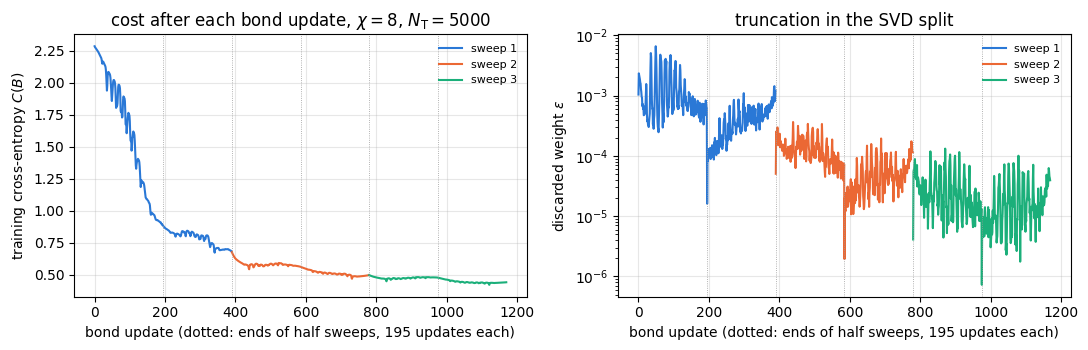

In [12]:
# ==============================================================================
# STEP 6: three sweeps, chi = 8, 5000 training images
# ==============================================================================
CHI_SWEEP, N_TRAIN_SWEEP, N_SWEEPS = 8, 5000, 3
As_sw, C_sw, hist_sw = train_sweeps(CHI_SWEEP, N_TRAIN_SWEEP, N_SWEEPS)
print(f"cross-entropy after the update at the first bond of sweep 1: {hist_sw[0]['cost'][0]:.4f}   (ln 10 = {np.log(10):.4f})")
for k, h in enumerate(hist_sw):
    print(f"sweep {k + 1}: cost at the last bond {h['cost'][-1]:.4f},  largest discarded weight {h['eps'].max():.1e},  "
          f"train acc {h['train']:.4f},  test acc {h['test']:.4f},  {h['time']:.1f} s")

F_sw = sweep_scores(As_sw, C_sw, feature_linear(X_TRAIN[:N_TRAIN_SWEEP]))
cost_full = float(cross_entropy(F_sw, jax.nn.one_hot(Y_TRAIN[:N_TRAIN_SWEEP], N_LABELS, dtype=RDTYPE)))
print(f"\ncross-entropy of the final MPS by full contraction: {cost_full:.4f}  "
      f"(last bond update reported {hist_sw[-1]['cost'][-1]:.4f})")
assert abs(cost_full - hist_sw[-1]["cost"][-1]) < 1e-2 * cost_full

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, h in enumerate(hist_sw):
    steps = np.arange(len(h["cost"])) + k * len(h["cost"])
    axes[0].plot(steps, h["cost"], color=PALETTE[k], label=f"sweep {k + 1}")
    axes[1].semilogy(steps, np.maximum(h["eps"], 1e-18), color=PALETTE[k], label=f"sweep {k + 1}")
for ax in axes:
    for t in range(1, 2 * N_SWEEPS):
        ax.axvline(t * (N_SITES - 1), color="0.6", lw=0.6, ls=":")
    ax.set_xlabel("bond update (dotted: ends of half sweeps, 195 updates each)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("training cross-entropy $C(B)$")
axes[1].set_ylabel(r"discarded weight $\varepsilon$")
axes[0].set_title(r"cost after each bond update, $\chi=8$, $N_{\rm T}=5000$")
axes[1].set_title("truncation in the SVD split")
fig.tight_layout()
plt.show()

**Interpretation.** The plotted $C(B)$ is the cross-entropy of the whole classifier on the 5000 training images after
each bond update, a training curve. It starts at $2.29$, close to $\ln10\approx2.30$ (all labels equally likely), falls
quickly during the first half sweep and then slowly: $0.68$, $0.50$ and $0.44$ at the end of the three sweeps. The test
accuracy rises from $81.55\,\%$ after one sweep to $86.9\,\%$ after three. The discarded weight is at most $6.6\times10^{-3}$ in the first sweep
and $1.3\times10^{-4}$ in the third: each update changes the bond tensor only slightly, so it stays close to rank $\chi$
(Section 6.3). The discarded weight drops sharply at the turning points of the sweeps (dotted lines), where the
updated bonds lie at the ends of the chain, next to the white margin of the images. The cross-entropy recomputed from the
final MPS by a full contraction, $0.4445$, agrees with the last reported value, $0.4431$, to within the effect of the last
truncation.

The accuracy after three sweeps is well below the $98\,\%$ that [[1]](#ref-1) reports for $\chi=20$. We have used a
twelfth of the training set, a smaller $\chi$, the linear map, a cross-entropy cost and a fixed number of small
gradient steps per bond; [[1]](#ref-1), Sec. VI, also converged within two or three sweeps. Section 7 trains the same model by differentiating through the whole contraction, and Section 7.5 compares
the two methods at the same $\chi$ and the same training images.

In [13]:
section_timer("7 automatic differentiation")

## 7. Training II: automatic differentiation of the whole contraction

In the second approach, used by [[2]](#ref-2), all tensors are updated at once. Each update uses a *mini-batch*: a
random subset of $N_{\rm b}=100$ training images. The cost is the cross-entropy (8) over the mini-batch, the scores come
from the full contraction of Section 5, and the gradient with respect to every parameter is computed by reverse-mode
automatic differentiation (`jax.grad`) and fed to Adam [[7]](#ref-7). One pass through all
training images, in shuffled mini-batches, is an *epoch*. Nothing is truncated and $\chi$ is fixed during training.

### 7.1 The gradient of a contraction is an environment

The score $f^\ell(\mathbf x)$ of Eq. (6) is linear in every single site tensor. For a site $j$ left of the label site,

$$f^\ell(\mathbf x)=\sum_{a,s,b}L_a\,\phi_s(x_j)\,A^{[j]s}_{ab}\,R^\ell_b
\quad\Longrightarrow\quad\frac{\partial f^\ell(\mathbf x)}{\partial A^{[j]s}_{ab}}=L_a\,\phi_s(x_j)\,R^\ell_b, \tag{11}$$

where $L$ is the image contracted with the sites left of $j$ and $R^\ell$ with all sites right of $j$, the label site
included. The derivative of a tensor-network contraction with respect to one tensor is the network with that tensor
removed: its *environment*. These are the same objects that the sweep caches. Reverse-mode differentiation of a chain
of matrix products computes all these environments in one backward pass: the forward pass stores the left vectors, the
backward pass builds the right vectors and combines them. The cell checks Eq. (11) for the full classifier, $N=196$,
$\chi=8$, with the environments built by `left_env_step` and `right_env_step` of the sweep code.

In [14]:
# ==============================================================================
# STEP 7: jax.grad of a score with respect to one site tensor = the environment of that tensor, Eq. (11)
# ==============================================================================
p_env = init_mps_params(jax.random.PRNGKey(7), N_SITES, 8, sigma=0.1)
phi_env = feature_linear(X_TRAIN[0])                                          # one image, (N, 2)
c_env, j_env, l_env = N_SITES // 2, 40, int(Y_TRAIN[0])

grad_ad = jax.grad(lambda p: mps_scores(p, phi_env)[l_env])(p_env)["A"][j_env]   # (chi, 2, chi)

ph1 = phi_env[None]                                                           # batch of one image for the env functions
L_env = jnp.zeros((1, 8), RDTYPE).at[:, 0].set(1.0)
for k in range(j_env):                                                        # sites 0 .. j-1
    L_env = left_env_step(L_env, p_env["A"][k], ph1[:, k])
R_env = jnp.zeros((1, 8), RDTYPE).at[:, 0].set(1.0)
for k in range(N_SITES - 1, c_env, -1):                                       # sites N-1 .. c+1 (A index k-1)
    R_env = right_env_step(R_env, p_env["A"][k - 1], ph1[:, k])
R_env = jnp.einsum("asb,ns,nb->na", p_env["lab"][:, :, l_env, :], ph1[:, c_env], R_env)   # label site, label l
for k in range(c_env - 1, j_env, -1):                                         # sites c-1 .. j+1
    R_env = right_env_step(R_env, p_env["A"][k], ph1[:, k])
grad_env = jnp.einsum("a,s,b->asb", L_env[0], phi_env[j_env], R_env[0])
err_env = max_abs(grad_ad - grad_env) / max_abs(grad_env)
print(f"site {j_env}, label {l_env}: max |jax.grad - L (x) phi (x) R| / max |L (x) phi (x) R| = {err_env:.1e}")
assert err_env < TOL

site 40, label 5: max |jax.grad - L (x) phi (x) R| / max |L (x) phi (x) R| = 2.9e-15


The gradient from `jax.grad` and the outer product of the two environments with the feature vector agree to
round-off. From the point of view of the tensors, automatic differentiation computes the same environments as the
sweep, for all sites at once, and changes all tensors by a small step. The sweep changes two tensors at a time, uses the environments of all training images at that bond, and
re-splits the pair with an SVD.

### 7.2 Two contraction orders

Equation (6) can be evaluated in any order of the matrix products. The order of Section 5.2 multiplies a vector by one
matrix after the other: $O(N\chi^2)$ operations, but $N$ sequential steps. [[2]](#ref-2), Fig. 4, contracts instead
all pixel legs first and then multiplies neighbouring *matrices* in pairs, halving the length of the chain in each
round: $O(N\chi^3)$ operations, but only $\log_2N$ rounds, each of which is a batch of independent matrix products that
parallelises well. The cell implements the pairwise order (padding the chain with identity matrices to a power of two
and rescaling each product), checks that both orders give the same scores, and times the cost and gradient on a batch
of 100 images.

In [15]:
# ==============================================================================
# STEP 8: pairwise ("parallel") contraction order and timing of both orders
# ==============================================================================
def _pairwise_product(M):
    """M[0] M[1] ... M[K-1] by rounds of pairwise products; returns (Prod / |Prod|, log |Prod|), Prod the product.

    IMPLEMENTATION  pad with identities to K2 = 2^ceil(log2 K) matrices; each round M <- M[0::2] @ M[1::2]
                    (one batched einsum), each product divided by its Frobenius norm, logs accumulated
    COST            O(K chi^3) operations in log2(K) rounds
    """
    K, chi = M.shape[0], M.shape[1]
    K2 = 1 << (K - 1).bit_length()
    M = jnp.concatenate([M, jnp.broadcast_to(jnp.eye(chi, dtype=M.dtype), (K2 - K, chi, chi))])
    lz = jnp.zeros((), RDTYPE)
    while M.shape[0] > 1:
        M = jnp.einsum("kab,kbc->kac", M[0::2], M[1::2])
        nm = jnp.linalg.norm(M, axis=(1, 2))
        M, lz = M / nm[:, None, None], lz + jnp.sum(jnp.log(nm))
    return M[0], lz


def mps_scores_pairwise(params, phi):
    """Same scores as mps_scores, contracted in the pairwise order."""
    A, lab = params["A"], params["lab"]
    c = phi.shape[0] // 2
    M = jnp.einsum("jasb,js->jab", A, jnp.concatenate([phi[:c], phi[c + 1:]]))
    ProdL, zl = _pairwise_product(M[:c])
    ProdR, zr = _pairwise_product(M[c:])
    return jnp.einsum("a,s,aslb,b->l", ProdL[0], phi[c], lab, ProdR[:, 0]) * jnp.exp(zl + zr)


def batch_cost(score_fn):
    def cost(params, phi, y):
        return cross_entropy(jax.vmap(score_fn, (None, 0))(params, phi), jax.nn.one_hot(y, N_LABELS, dtype=RDTYPE))
    return cost


phi_b, y_b = feature_linear(X_TRAIN[:100]), Y_TRAIN[:100]
f_seq = jax.vmap(mps_scores, (None, 0))(p_env, phi_b)
f_pair = jax.vmap(mps_scores_pairwise, (None, 0))(p_env, phi_b)
err_order = max_abs(f_seq - f_pair) / max_abs(f_seq)
print(f"max |f_sequential - f_pairwise| / max |f| = {err_order:.1e}")
assert err_order < TOL

for chi_t in (8, 16, 32):
    p_t = init_mps_params(jax.random.PRNGKey(8), N_SITES, chi_t, sigma=0.1)
    row = []
    for name, fn in (("sequential", mps_scores), ("pairwise", mps_scores_pairwise)):
        vg = jax.jit(jax.value_and_grad(batch_cost(fn)))
        jax.block_until_ready(vg(p_t, phi_b, y_b))                             # compile
        ts = []
        for _ in range(5):
            t0 = time.perf_counter()
            jax.block_until_ready(vg(p_t, phi_b, y_b))
            ts.append(time.perf_counter() - t0)
        row.append(f"{name} {1e3 * min(ts):7.1f} ms")
    print(f"chi = {chi_t:2d}: cost + gradient on 100 images:  " + ",   ".join(row))

max |f_sequential - f_pairwise| / max |f| = 2.3e-14


chi =  8: cost + gradient on 100 images:  sequential     5.1 ms,   pairwise    19.4 ms


chi = 16: cost + gradient on 100 images:  sequential    30.4 ms,   pairwise    77.8 ms


chi = 32: cost + gradient on 100 images:  sequential   136.1 ms,   pairwise   299.5 ms


Both orders give the same scores. On this CPU the sequential order is the faster one at every $\chi$ tried (the
timings are the best of five calls): it does a factor $\chi$ fewer operations, and the CPU gains little from the
extra parallelism of the pairwise rounds. [[2]](#ref-2) found the pairwise order faster on their hardware and library,
where the batched matrix products of each round run in parallel; which order wins is a property of the machine, and
the timing has to decide. We train with the sequential order.

### 7.3 Initialisation and normalisation

Automatic differentiation of a product of 196 matrices is sensitive to the scale of the result. A random MPS gives
scores of order $10^{77}$ (Section 5.3). With scores that large the cross-entropy is almost linear in them,
$C\approx\max_\ell f^\ell-f^{y}$: the gradient $p-Y$ of Eq. (8) only says which label wins and carries no information on the margin, and the
gradients with respect to the tensors scale with the scores themselves, so they span many orders of magnitude across
images and are dominated by the images with the largest scores. `init_mps_params` therefore starts from identity matrices, $A^{[j]0}=A^{[j]1}=\mathbb 1$, plus noise of size
$10^{-2}$. With the linear map, $M^{[j]}=\phi_0\mathbb 1+\phi_1\mathbb 1=\mathbb 1$ for every pixel value, so every
image starts with scores of order one. With the cosine–sine map,
$M^{[j]}=(\cos\frac{\pi x_j}2+\sin\frac{\pi x_j}2)\mathbb 1$, a factor between $1$ (white or black pixel) and $\sqrt2$
(grey pixel, $x=\frac12$): the initial score of an image is $\prod_j(\cos\frac{\pi x_j}2+\sin\frac{\pi x_j}2)$ and
depends exponentially on the number of grey pixels.

The cell prints the spread of the initial scores for both maps and compares three variants on 5000 images with
$\chi=8$: the linear map with the cross-entropy (the choice of this notebook), the cosine–sine map with the
cross-entropy, and the linear map with the quadratic cost of [[1]](#ref-1). The first variant is trained for six
epochs, and this run is also the one analysed in Section 7.5; the cell prints its first three epochs. The other two
are trained for three epochs. The training loop compiles one epoch into a `lax.scan` over shuffled mini-batches; the
parameters are flattened into one vector by `ravel_pytree` so that the engine's Adam update applies to them unchanged.

In [16]:
# ==============================================================================
# STEP 9: training by automatic differentiation; initialisation and cost variants
# ==============================================================================
def quadratic_cost(F, Y):
    """Quadratic cost of [1], Eq. (6), per image: (1/(2 N_T)) sum_n sum_l (f_n^l - Y_nl)^2."""
    return 0.5 * jnp.mean(jnp.sum((F - Y) ** 2, axis=1))


def train_autodiff(chi, n_train, epochs, lr=3e-3, batch=100, fmap=feature_linear, cost="ce",
                   key=jax.random.PRNGKey(9), evaluate_every_epoch=False, x_train=None, y_train=None,
                   x_test=None, y_test=None):
    """Adam on the cross-entropy (or quadratic cost) of the MPS classifier, gradients by jax.grad.

    IMPLEMENTATION  params -> one flat vector theta (ravel_pytree); one epoch = lax.scan over shuffled mini-batches of
                    `batch` images, each step value_and_grad + adam_update; the whole epoch is one jit-compiled call,
                    with the data passed as arguments (not captured as compile-time constants)
    RETURNS         params, history (list of dicts: loss, time, and test accuracy if requested)
    """
    x_train = X_TRAIN if x_train is None else x_train
    y_train = Y_TRAIN if y_train is None else y_train
    x_test = X_TEST if x_test is None else x_test
    y_test = Y_TEST if y_test is None else y_test
    phi, y = fmap(x_train[:n_train]), y_train[:n_train]
    k_init, k_ep = jax.random.split(key)
    theta, unravel = ravel_pytree(init_mps_params(k_init, N_SITES, chi))
    cost_fn = cross_entropy if cost == "ce" else quadratic_cost

    def loss(theta, phi_b, y_b):
        F = jax.vmap(mps_scores, (None, 0))(unravel(theta), phi_b)
        return cost_fn(F, jax.nn.one_hot(y_b, N_LABELS, dtype=RDTYPE))

    @jax.jit
    def epoch(theta, state, key, phi, y):
        order = jax.random.permutation(key, n_train)[: (n_train // batch) * batch].reshape(-1, batch)

        def step(carry, idx):
            theta, state = carry
            val, g = jax.value_and_grad(loss)(theta, phi[idx], y[idx])
            theta, state = adam_update(theta, g, state, lr=lr)
            return (theta, state), val
        (theta, state), vals = lax.scan(step, (theta, state), order)
        return theta, state, jnp.mean(vals)

    state, hist = adam_init(theta), []
    for ep, k in enumerate(jax.random.split(k_ep, epochs)):
        t0 = time.perf_counter()
        theta, state, val = epoch(theta, state, k, phi, y)
        val = float(val)
        h = dict(loss=val, time=time.perf_counter() - t0)
        if evaluate_every_epoch or ep == epochs - 1:
            h["test"] = evaluate(unravel(theta), fmap(x_test), y_test)
        hist.append(h)
    return unravel(theta), hist


@jax.jit
def scores_batch(params, phi):
    return jax.vmap(mps_scores, (None, 0))(params, phi)


def evaluate(params, phi, y):
    """Test accuracy: argmax_l f^l(x) against the labels."""
    return accuracy_from_scores(scores_batch(params, phi), y)


# spread of the initial scores over 5000 images for the two maps
p0 = init_mps_params(jax.random.PRNGKey(10), N_SITES, 8)
for name, fmap in (("linear", feature_linear), ("cosine-sine", feature_cos_sin)):
    f0 = scores_batch(p0, fmap(X_TRAIN[:5000]))
    lf = np.log10(np.abs(np.asarray(f0[:, 0])))
    print(f"{name:12s} map, initial MPS: log10 f^0 over 5000 images: min {lf.min():6.2f}, median {np.median(lf):6.2f}, "
          f"max {lf.max():6.2f}")

print()
params_ad8, hist_ad8 = train_autodiff(8, 5000, 6, evaluate_every_epoch=True)     # also the run of Section 7.5
VARIANTS = {"linear map, cross-entropy": hist_ad8[:3]}
for name, kw in (("cosine-sine map, cross-entropy", dict(fmap=feature_cos_sin)),
                 ("linear map, quadratic cost", dict(cost="quadratic"))):
    _, VARIANTS[name] = train_autodiff(8, 5000, 3, evaluate_every_epoch=True, **kw)
for name, h in VARIANTS.items():
    print(f"{name:32s} test accuracy after epochs 1-3: " + ", ".join(f"{e['test']:.4f}" for e in h))

linear       map, initial MPS: log10 f^0 over 5000 images: min  -0.07, median  -0.01, max   0.06


cosine-sine  map, initial MPS: log10 f^0 over 5000 images: min   0.65, median   4.32, max   7.91



linear map, cross-entropy        test accuracy after epochs 1-3: 0.8116, 0.8941, 0.9158
cosine-sine map, cross-entropy   test accuracy after epochs 1-3: 0.1117, 0.1595, 0.2944
linear map, quadratic cost       test accuracy after epochs 1-3: 0.0982, 0.1901, 0.2858


With the linear map the initial scores of all images lie between $10^{-0.07}$ and $10^{0.06}$: the initial MPS treats
every image alike, and the training has a well-scaled starting point. With the cosine–sine map the initial scores
range from $10^{0.65}$ to $10^{7.9}$, set by how many grey pixels an image has. With scores that large the
cross-entropy is in its linear regime and the gradients are dominated by the images with the most grey pixels, and the
training reaches only $29\,\%$ after three epochs, against $91.6\,\%$ with the linear map. The quadratic cost with the linear map learns, but much more slowly ($28.6\,\%$ after three epochs): it
asks for the exact values $f^\ell=\delta_{\ell y}$, while the cross-entropy only asks for the right ordering of the
scores. Both observations hold for our short training runs from this initial
state; with long training, the authors of [[2]](#ref-2) report similar final accuracies for the two costs (their Fig. 7).

### 7.4 What not to differentiate, and memory

* **No gradients through a truncated SVD.** Neither training method differentiates through an SVD: automatic
  differentiation keeps $\chi$ fixed, and the sweep computes its gradient before the split. The backward formula of
  the SVD contains, for every pair of singular values, the factors $1/(s_j-s_i)\pm1/(s_j+s_i)$, that is
  $2s_j/(s_j^2-s_i^2)$ and $2s_i/(s_j^2-s_i^2)$ ([[8]](#ref-8), Eq. (4)), which diverge when two singular values become
  degenerate; a truncation adds jumps of the kept subspace when two singular values at the truncation boundary cross.
  The cell differentiates a quantity that depends on the singular vectors of a $2\times2$ matrix with singular values
  $1$ and $1-\delta$.
* **Memory.** Reverse mode stores the intermediates of the forward pass. Here these are, per image, the $N-1$
  matrices $M^{[j]}$ and the $N$ vectors of the scans, $O(N_{\rm b}N\chi^2)$ numbers per mini-batch; the matrices alone
  take $N_{\rm b}(N-1)\chi^2$ numbers. `jax.checkpoint` trades memory for time: a function wrapped in it stores only its
  inputs and recomputes its intermediates in the backward pass (the checkpointing technique discussed for tensor
  networks in [[8]](#ref-8), Sec. III B). To save memory the wrapped scan body must itself form $M^{[j]}$ from
  $A^{[j]}$ and $\phi(x_j)$; if the matrices are formed outside it, they are stored anyway. The cell compares the
  memory of the compiled gradient, as reported by XLA, for the plain contraction and for the checkpointed one at
  $\chi=16$ on 100 images, and checks that the gradients agree.

In [17]:
# ==============================================================================
# STEP 10: SVD gradients near degenerate singular values; jax.checkpoint
# ==============================================================================
def singular_vector_derivative(delta):
    """dg/dt at t = 0 for g(t) = u_0 u_1, u the first left singular vector of A(t) = [[1, t], [t, 1 - delta]].

    MATH   A(t) is symmetric positive definite, its singular vectors are its eigenvectors, rotated by the angle theta
           with tan(2 theta) = 2 t / delta;  g = cos(theta) sin(theta) (independent of the sign of u), so dg/dt = 1/delta
    """
    def g(t):
        U, S, Vh = jnp.linalg.svd(jnp.array([[1.0, t], [t, 1.0 - delta]], dtype=RDTYPE))
        return U[0, 0] * U[1, 0]
    return jax.grad(g)(jnp.zeros((), RDTYPE))


for delta in (1e-1, 1e-3, 1e-5, 1e-7):
    print(f"singular values 1 and 1 - {delta:.0e}:  dg/dt by jax.grad = {float(singular_vector_derivative(delta)):.4e},  "
          f"1/delta = {1 / delta:.4e}")


def mps_scores_checkpointed(params, phi):
    """mps_scores with a jax.checkpoint scan body that forms M_j = sum_s phi_s(x_j) A_j^s itself.

    MEMORY  the backward pass stores only the scan inputs (A_j, phi_j) and the carried vectors, and recomputes M_j
    """
    A, lab = params["A"], params["lab"]
    N, chi = phi.shape[0], A.shape[1]
    c = N // 2

    @jax.checkpoint
    def body(carry, inp):
        v, lz = carry
        Aj, phij = inp
        v = v @ jnp.einsum("asb,s->ab", Aj, phij)
        nv = jnp.linalg.norm(v)
        return (v / nv, lz + jnp.log(nv)), None
    e0 = jnp.zeros(chi, RDTYPE).at[0].set(1.0)
    (vl, zl), _ = lax.scan(body, (e0, jnp.zeros((), RDTYPE)), (A[:c], phi[:c]))
    A_right = jnp.transpose(A[c:], (0, 3, 2, 1))[::-1]                          # transposed matrices, from the right end
    (vr, zr), _ = lax.scan(body, (e0, jnp.zeros((), RDTYPE)), (A_right, phi[c + 1:][::-1]))
    return jnp.einsum("a,s,aslb,b->l", vl, phi[c], lab, vr) * jnp.exp(zl + zr)


g_plain = jax.grad(batch_cost(mps_scores))(p_env, phi_b, y_b)
g_ckpt = jax.grad(batch_cost(mps_scores_checkpointed))(p_env, phi_b, y_b)
err_ckpt = max(max_abs(g_plain[k] - g_ckpt[k]) / max_abs(g_plain[k]) for k in g_plain)
print(f"\njax.checkpoint: max relative difference of the gradients = {err_ckpt:.1e}")
assert err_ckpt < TOL

p16 = init_mps_params(jax.random.PRNGKey(8), N_SITES, 16, sigma=0.1)
print(f"chi = 16, 100 images: the matrices M_j alone take {100 * (N_SITES - 1) * 16 ** 2 * 8 / 1e6:.1f} MB")
for name, fn in (("plain contraction", mps_scores), ("checkpointed body", mps_scores_checkpointed)):
    compiled = jax.jit(jax.grad(batch_cost(fn))).lower(p16, phi_b, y_b).compile()
    mem = compiled.memory_analysis()
    print(f"   gradient, {name:18s}: temporary memory of the compiled function {mem.temp_size_in_bytes / 1e6:7.1f} MB")

singular values 1 and 1 - 1e-01:  dg/dt by jax.grad = 1.0000e+01,  1/delta = 1.0000e+01
singular values 1 and 1 - 1e-03:  dg/dt by jax.grad = 1.0000e+03,  1/delta = 1.0000e+03
singular values 1 and 1 - 1e-05:  dg/dt by jax.grad = 1.0000e+05,  1/delta = 1.0000e+05
singular values 1 and 1 - 1e-07:  dg/dt by jax.grad = 1.0000e+07,  1/delta = 1.0000e+07



jax.checkpoint: max relative difference of the gradients = 1.2e-15
chi = 16, 100 images: the matrices M_j alone take 39.9 MB


   gradient, plain contraction : temporary memory of the compiled function   125.8 MB


   gradient, checkpointed body : temporary memory of the compiled function     4.7 MB


For the matrix $A(t)=\begin{pmatrix}1&t\\t&1-\delta\end{pmatrix}$ the singular vectors are rotated by the angle
$\theta$ with $\tan2\theta=2t/\delta$, so $g=\cos\theta\sin\theta$ has the derivative $1/\delta$ at $t=0$, and
`jax.grad` through `jnp.linalg.svd` reproduces it: the derivative grows without bound as the singular values approach
each other, as the denominators $s_j^2-s_i^2\approx2\delta$ predict. In a training loop that differentiates through an
SVD, two nearly equal singular values produce enormous gradients; they are exact for quantities that depend on
individual singular vectors, and numerically unstable even for costs in which the divergent terms cancel
analytically, which is why [[8]](#ref-8) broadens them.

The checkpointed contraction gives the same gradient as the plain one and needs $4.7\,$MB of temporary memory instead of
$125.8\,$MB at $\chi=16$ on 100 images; the matrices $M^{[j]}$ alone account for $39.9\,$MB. The price is a second evaluation
of the forward pass during the backward pass.

### 7.5 Training run and comparison with the sweep

The run with the linear map and the cross-entropy of Section 7.3 used the settings of the sweep run of Section 6.7:
$\chi=8$ and the same 5000 training images. The cell prints all six of its epochs and compares the two methods.

In [18]:
# ==============================================================================
# STEP 11: chi = 8, 5000 images, 6 epochs; comparison with the sweeps
# ==============================================================================
for k, h in enumerate(hist_ad8):                                              # the run of Section 7.3
    print(f"epoch {k + 1}: training cross-entropy (mean over the epoch) {h['loss']:.4f},  test acc {h['test']:.4f},  "
          f"{h['time']:.2f} s")

t_sweep = np.mean([h["time"] for h in hist_sw[1:]])
t_epoch = np.mean([h["time"] for h in hist_ad8[1:]])
print(f"\n{'method':34s} {'test acc':>9s} {'time per pass':>15s} {'total':>8s}")
print(f"{'sweeps, 3 sweeps':34s} {hist_sw[-1]['test']:9.4f} {t_sweep:12.2f} s  {sum(h['time'] for h in hist_sw):6.1f} s")
print(f"{'automatic differentiation, 6 epochs':34s} {hist_ad8[-1]['test']:9.4f} {t_epoch:12.2f} s  "
      f"{sum(h['time'] for h in hist_ad8):6.1f} s")

epoch 1: training cross-entropy (mean over the epoch) 1.1957,  test acc 0.8116,  0.72 s
epoch 2: training cross-entropy (mean over the epoch) 0.4444,  test acc 0.8941,  0.36 s
epoch 3: training cross-entropy (mean over the epoch) 0.2702,  test acc 0.9158,  0.31 s
epoch 4: training cross-entropy (mean over the epoch) 0.2090,  test acc 0.9082,  0.46 s
epoch 5: training cross-entropy (mean over the epoch) 0.1903,  test acc 0.9212,  0.45 s
epoch 6: training cross-entropy (mean over the epoch) 0.1665,  test acc 0.9321,  0.46 s

method                              test acc   time per pass    total
sweeps, 3 sweeps                      0.8692         9.02 s    27.2 s
automatic differentiation, 6 epochs    0.9321         0.41 s     2.8 s


**Interpretation.** At the same bond dimension and on the same 5000 images, Adam with gradients of the whole
contraction reaches $93.2\,\%$ after six epochs in about 3 s, three sweeps $86.9\,\%$ in about half a minute; after one pass
through the data both are near $81\,\%$. One epoch costs less than half a second and one sweep about 9 s (wall-clock
times on this CPU, which vary between runs; the first sweep and the first epoch, which include compilation, are
excluded from the per-pass averages). Two differences between the methods explain this at our scale:

* a sweep spends $2\times195$ local optimisations, each over all 5000 images, while an epoch of Adam makes 50
  updates of all tensors at once, each on 100 images. The mini-batches give many more updates per pass through the data;
* the local gradient step uses the conservative step $1/\Lambda$, set by the largest curvature; directions of small
  curvature move slowly. Adam rescales every parameter separately.

One property of the sweep is not used here: with a cutoff on the singular values instead of a fixed $\chi$, every
bond can grow or shrink to what the data need ([[1]](#ref-1), Sec. V), while automatic differentiation keeps $\chi$
fixed. The sweep also has no learning rate to tune: its step is set by the curvature. Its sensitivity to the scale of the
environments is removed by the gauge rescaling of Section 6.5. Automatic differentiation depends on a well-scaled
start, as Section 7.3 showed. Because the second method is the faster one here, Section 8 uses it for the systematic
study.

In [19]:
section_timer("8 results")

## 8. Results

### 8.1 Accuracy against bond dimension

We train with $\chi=1,2,4,8,16$ on 5000 images for six epochs. The run with $\chi=8$ is the one of Section 7.5.

In [20]:
# ==============================================================================
# STEP 12: test accuracy against chi (5000 training images, 6 epochs)
# ==============================================================================
CHIS = (1, 2, 4, 8, 16)
ACC_CHI = {}
for chi in CHIS:
    if chi == 8:
        ACC_CHI[chi] = (hist_ad8[-1]["test"], sum(h["time"] for h in hist_ad8))
        continue
    _, h = train_autodiff(chi, 5000, 6)
    ACC_CHI[chi] = (h[-1]["test"], sum(e["time"] for e in h))
for chi in CHIS:
    n_par = (N_SITES - 1) * 2 * chi ** 2 + 2 * N_LABELS * chi ** 2
    print(f"chi = {chi:2d}: parameters {n_par:7d},  test accuracy {ACC_CHI[chi][0]:.4f},  training time {ACC_CHI[chi][1]:5.1f} s")

chi =  1: parameters     410,  test accuracy 0.1135,  training time   0.7 s
chi =  2: parameters    1640,  test accuracy 0.6824,  training time   0.8 s
chi =  4: parameters    6560,  test accuracy 0.9082,  training time   0.9 s
chi =  8: parameters   26240,  test accuracy 0.9321,  training time   2.8 s
chi = 16: parameters  104960,  test accuracy 0.9292,  training time   8.2 s


With $\chi=1$ the classifier fails completely: $11.35\,\%$ is exactly the fraction of the digit 1 in the test set, so
it predicts the same label for every image. The reason is the single label leg. With $\chi=1$ every tensor is a
$2$-vector, and Eq. (6) becomes $f^\ell(\mathbf x)=g(\mathbf x)\,(a^\ell\phi_0(x_c)+b^\ell\phi_1(x_c))$: the product
$g$ of all other sites is the same for every label, and only the pixel at the label site can distinguish labels. Our
label site $c=98$ is the first pixel of row 7, which is white in practically every image. A product state can be a good
classifier when every label has its own product state: [[3]](#ref-3), Table I, reaches $91.1\,\%$ with such a model on
the full MNIST data. With one label leg the bond dimension carries all information about the other pixels to the label
site: $\chi=2$ reaches $68\,\%$, $\chi=4$ $90.8\,\%$, $\chi=8$ $93.2\,\%$, and $\chi=16$ no more ($92.9\,\%$) at this
training-set size and number of epochs. The training time is nearly flat up to $\chi=4$, where fixed overheads
dominate, and grows by a factor of about 3 from $\chi=8$ to $\chi=16$, where the operation count grows by $\chi^2$,
a factor 4.

### 8.2 Accuracy against the size of the training set

With $\chi=8$ fixed we vary the number of training images from 1000 to the 20000 stored, at six epochs each, and
record the training and test accuracy.

n_train =  1000: training accuracy 0.8990,  test accuracy 0.8226


n_train =  2000: training accuracy 0.9405,  test accuracy 0.8904


n_train =  5000: training accuracy 0.9672,  test accuracy 0.9321


n_train = 10000: training accuracy 0.9597,  test accuracy 0.9425


n_train = 20000: training accuracy 0.9558,  test accuracy 0.9442


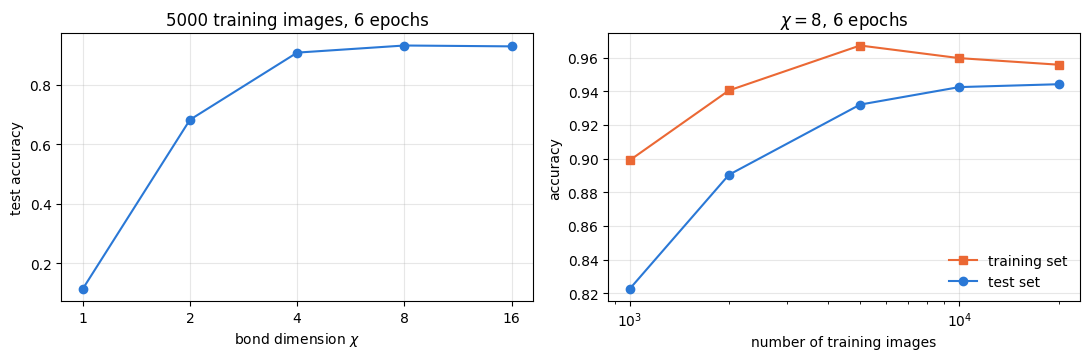

In [21]:
# ==============================================================================
# STEP 13: test and training accuracy against the number of training images (chi = 8)
# ==============================================================================
N_TRAINS = (1000, 2000, 5000, 10000, 20000)
ACC_N = {}
for n_tr in N_TRAINS:
    if n_tr == 5000:
        params_n = params_ad8
    else:
        params_n, _ = train_autodiff(8, n_tr, 6)
    ACC_N[n_tr] = (evaluate(params_n, feature_linear(X_TRAIN[:n_tr]), Y_TRAIN[:n_tr]),
                   evaluate(params_n, feature_linear(X_TEST), Y_TEST))
    print(f"n_train = {n_tr:5d}: training accuracy {ACC_N[n_tr][0]:.4f},  test accuracy {ACC_N[n_tr][1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].plot(CHIS, [ACC_CHI[c][0] for c in CHIS], "o-", color=PALETTE[0])
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(CHIS)
axes[0].set_xticklabels([str(c) for c in CHIS])
axes[0].set_xlabel(r"bond dimension $\chi$")
axes[0].set_ylabel("test accuracy")
axes[0].set_title("5000 training images, 6 epochs")
axes[1].semilogx(N_TRAINS, [ACC_N[n][0] for n in N_TRAINS], "s-", color=PALETTE[1], label="training set")
axes[1].semilogx(N_TRAINS, [ACC_N[n][1] for n in N_TRAINS], "o-", color=PALETTE[0], label="test set")
axes[1].set_xlabel("number of training images")
axes[1].set_ylabel("accuracy")
axes[1].set_title(r"$\chi=8$, 6 epochs")
axes[1].legend()
fig.tight_layout()
plt.show()

The gap between training and test accuracy measures overfitting. With 1000 images it is 7.6 percentage points
($89.9\,\%$ against $82.3\,\%$); with 20000 images it is 1.2 points, and the test accuracy has risen to $94.4\,\%$.
At 5000 images, going to 20000 images gains 1.2 points, going from $\chi=8$ to $\chi=16$ gains nothing. Between 10000
and 20000 images the test accuracy rises by only 0.2 points ($94.25\,\%$ to $94.42\,\%$): at $\chi=8$ and six epochs
it is close to saturation.

### 8.3 The best model and its confusion matrix

Our largest run uses $\chi=16$, all 20000 stored training images and eight epochs. For this larger model and longer
run we lowered the learning rate to $2\times10^{-3}$; it was not tuned further. The confusion matrix counts, for every true label (row), how often each label was predicted
(column).

test accuracy after each epoch: 0.9277, 0.9443, 0.9566, 0.9535, 0.9633, 0.9587, 0.9562, 0.9627
training time 43.7 s


final test accuracy 0.9627  (373 of 10000 test images misclassified)
accuracy per label: 0: 0.991, 1: 0.983, 2: 0.966, 3: 0.950, 4: 0.890, 5: 0.954, 6: 0.974, 7: 0.965, 8: 0.988, 9: 0.963
predictions per label minus true count per label: 0: +27, 1: +0, 2: +2, 3: -37, 4: -102, 5: -19, 6: -6, 7: -3, 8: +70, 9: +68


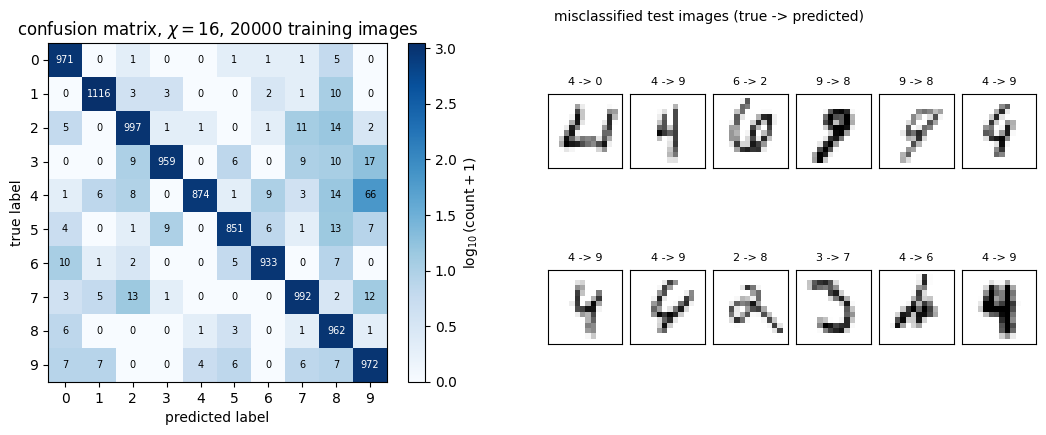

In [22]:
# ==============================================================================
# STEP 14: chi = 16, 20000 images, 8 epochs; confusion matrix
# ==============================================================================
params_best, hist_best = train_autodiff(16, 20000, 8, lr=2e-3, evaluate_every_epoch=True)
print("test accuracy after each epoch:", ", ".join(f"{h['test']:.4f}" for h in hist_best))
print(f"training time {sum(h['time'] for h in hist_best):.1f} s")

pred_best = np.asarray(jnp.argmax(scores_batch(params_best, feature_linear(X_TEST)), axis=1))
conf = np.zeros((N_LABELS, N_LABELS), dtype=int)
np.add.at(conf, (np.asarray(Y_TEST), pred_best), 1)
acc_best = np.trace(conf) / conf.sum()
print(f"final test accuracy {acc_best:.4f}  ({conf.sum() - np.trace(conf)} of {conf.sum()} test images misclassified)")
per_label = np.diag(conf) / conf.sum(axis=1)
print("accuracy per label:", ", ".join(f"{l}: {a:.3f}" for l, a in enumerate(per_label)))
print("predictions per label minus true count per label:", ", ".join(
    f"{l}: {d:+d}" for l, d in enumerate(conf.sum(axis=0) - conf.sum(axis=1))))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw=dict(width_ratios=[1.1, 1]))
im = axes[0].imshow(np.log10(conf + 1), cmap="Blues")
for i in range(N_LABELS):
    for k in range(N_LABELS):
        axes[0].text(k, i, str(conf[i, k]), ha="center", va="center", fontsize=7,
                     color="white" if conf[i, k] > 300 else "black")
axes[0].set_xticks(range(N_LABELS))
axes[0].set_yticks(range(N_LABELS))
axes[0].set_xlabel("predicted label")
axes[0].set_ylabel("true label")
axes[0].set_title(r"confusion matrix, $\chi=16$, 20000 training images")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], label=r"$\log_{10}(\mathrm{count}+1)$")
wrong = np.nonzero(pred_best != np.asarray(Y_TEST))[0][:12]
axes[1].axis("off")
for k, idx in enumerate(wrong):
    ax = fig.add_axes([0.56 + 0.072 * (k % 6), 0.52 - 0.40 * (k // 6), 0.065, 0.32])
    ax.imshow(np.asarray(X_TEST[idx]).reshape(14, 14), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"{int(Y_TEST[idx])} -> {pred_best[idx]}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.text(0.70, 0.93, "misclassified test images (true -> predicted)", ha="center", fontsize=10)
plt.show()

The best model classifies $96.3\,\%$ of the test images correctly. The largest off-diagonal entry is a 4 taken for a
9 (66 images), and the digit 4 has the lowest accuracy, $89.0\,\%$. Column 8 of the confusion matrix collects errors
from almost every row: the model predicts the label 8 for 70 images more than there are eights in the test set, and
the label 9 for 68 more, while it predicts the label 4 for 102 images fewer than there are fours. Many misclassified
examples are badly written or ambiguous at $14\times14$ pixels. Over the last four epochs the test accuracy
fluctuates by up to 0.7 percentage points (between $95.6\,\%$ and $96.3\,\%$), the noise of mini-batch training with a
constant learning rate.

### 8.4 Comparison with the published results

| | images (train / test) | pixels | $\chi$ | training | test accuracy |
|---|---|---|---|---|---|
| [[1]](#ref-1), Sec. VI | 60000 / 10000 | $14\times14$ | 10 | sweeps, quadratic cost | about $95\,\%$ |
| [[1]](#ref-1), Sec. VI | 60000 / 10000 | $14\times14$ | 20 | sweeps, quadratic cost | about $98\,\%$ |
| [[1]](#ref-1), Sec. VI | 60000 / 10000 | $14\times14$ | 120 | sweeps, quadratic cost | $99.03\,\%$ |
| [[2]](#ref-2), Sec. III, Fig. 7 | 60000 / 10000 | $28\times28$ | 10–100 | Adam, cross-entropy | about $98\,\%$ |
| this notebook, Section 6.7 | 5000 / 10000 | $14\times14$ | 8 | 3 sweeps, cross-entropy | $86.9\,\%$ |
| this notebook, Section 7.5 | 5000 / 10000 | $14\times14$ | 8 | Adam, 6 epochs, cross-entropy | $93.2\,\%$ |
| this notebook, Section 8.3 | 20000 / 10000 | $14\times14$ | 16 | Adam, 8 epochs, cross-entropy | $96.3\,\%$ |

The published numbers come from runs on the full training set of 60000 images, with tens of epochs ([[2]](#ref-2)
needed about 50 to converge, its Sec. III) or with larger bond dimensions ([[1]](#ref-1) reports test errors of about
$5\,\%$ for $m=10$, $2\,\%$ for $m=20$ and $0.97\,\%$ for $m=120$). Our runs use a third of the training images or less, a
few epochs and a few minutes of one CPU. At $\chi=8$ and six epochs our test accuracy saturates near $94.4\,\%$ between
10000 and 20000 images (Section 8.2), while $\chi=16$ and eight epochs on the same 20000 images reach $96.3\,\%$: at this
size of the training set the length of the training and $\chi$ matter as much as the number of images, and the gap to
the published accuracies is consistent with smaller training sets and shorter training. The independence of the accuracy from $\chi$ above $\chi\approx10$ reported in [[2]](#ref-2)
matches the flattening of our curve in Section 8.1.

### 8.5 Fashion-MNIST

The same classifier, unchanged, can be trained on Fashion-MNIST [[9]](#ref-9): $28\times28$ grey-scale images of ten
kinds of clothing, a harder problem with the same format. The file `../data/fashion_mnist_14x14.npz` holds the first
10000 training and 5000 test images at $14\times14$ pixels; Fashion-MNIST is distributed under the MIT licence
(`data/README.md`). [[2]](#ref-2) reports $88\,\%$ test accuracy on the full data set.

In [23]:
# ==============================================================================
# STEP 15: Fashion-MNIST, chi = 8, 10000 training images, 6 epochs
# ==============================================================================
FASHION = np.load("../data/fashion_mnist_14x14.npz")
print(str(FASHION["info"]))
FX_TRAIN = jnp.asarray(FASHION["x_train"].reshape(-1, N_SITES) / 255.0, dtype=RDTYPE)
FY_TRAIN = jnp.asarray(FASHION["y_train"].astype(np.int32))
FX_TEST = jnp.asarray(FASHION["x_test"].reshape(-1, N_SITES) / 255.0, dtype=RDTYPE)
FY_TEST = jnp.asarray(FASHION["y_test"].astype(np.int32))
params_f, hist_f = train_autodiff(8, 10000, 6, x_train=FX_TRAIN, y_train=FY_TRAIN, x_test=FX_TEST, y_test=FY_TEST)
acc_f_train = evaluate(params_f, feature_linear(FX_TRAIN), FY_TRAIN)
print(f"\nFashion-MNIST, chi = 8, 10000 images, 6 epochs: training accuracy {acc_f_train:.4f}, "
      f"test accuracy {hist_f[-1]['test']:.4f},  {sum(h['time'] for h in hist_f):.1f} s")

Fashion-MNIST clothing images. Source: http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/. Licence: MIT. Reduced to 14x14 by 2x2 averaging; first 10000 training and first 5000 test images. Classes: 0 T-shirt/top, 1 trouser, 2 pullover, 3 dress, 4 coat, 5 sandal, 6 shirt, 7 sneaker, 8 bag, 9 ankle boot. See data/README.md.



Fashion-MNIST, chi = 8, 10000 images, 6 epochs: training accuracy 0.8054, test accuracy 0.7816,  4.6 s


On Fashion-MNIST the same model and settings reach $78.2\,\%$, ten points below the $88\,\%$ of [[2]](#ref-2), which
trained on all 60000 images of $28\times28$ pixels for many more epochs (its Fig. 6). The training accuracy,
$80.5\,\%$, is close to the test accuracy: unlike the digits, the model is still far from fitting its training set,
and longer training or a larger $\chi$ may help (Exercise 5). Clothing is harder than digits for the same model, as
in [[2]](#ref-2).

In [24]:
section_timer("9 entanglement")

## 9. Entanglement of the data and of the trained classifier

An MPS with bond dimension $\chi$ can carry at most $\log_2\chi$ bits of entanglement entropy across any cut
([notebook 18, matrix product states](../ch07_tensor_networks/18_mps_tebd.ipynb), Section 2.2). A trained classifier with $\chi=16$ therefore represents, for each label, a state of 196
qubits with at most 4 bits of entanglement across every bond. Which state does it represent? [[3]](#ref-3), Sec. III,
considers a natural candidate: the superposition of the product states of all training images of one class,

$$\vert\Sigma_\ell\rangle=\sum_{i:\,y_i=\ell}\vert\Phi(\mathbf x_i)\rangle, \tag{12}$$

its Eq. (10). As a weight vector, $W^\ell=\Sigma_\ell$ gives the scores

$$f^\ell(\mathbf x)=\langle\Sigma_\ell\vert\Phi(\mathbf x)\rangle=\sum_{i:\,y_i=\ell}K(\mathbf x,\mathbf x_i), \tag{13}$$

a sum of kernel values (4) over the training images of class $\ell$. In the map of Eq. (2) all kernel values are
non-negative, so every training image of class $\ell$ has $f^\ell\geq1$ from its own term. Because the kernel is so
peaked (Section 4.2), the sum is usually dominated by the most similar training image, and Eq. (13) behaves much like
a *nearest-neighbour rule*, which gives an image the label of the most similar training image. [[3]](#ref-3) observed
reasonable accuracies of this classifier on the training and test sets, and found that $\vert\Sigma_\ell\rangle$ is far
too entangled to be represented by the MPS of [[1]](#ref-1); it concludes that the trained MPS must represent a very
different state. We measure the accuracy of Eq. (13) and reproduce the conclusion at our scale.

### 9.1 The sum-state classifier

The cell evaluates Eq. (13) with the cosine–sine map, with the first 5000 training images as the $\Sigma_\ell$, on
these 5000 images and on the first 2000 test images. The kernel matrix is built as a product over pixels of the
$(2000\times5000)$ matrices of local overlaps, one per pixel.

In [25]:
# ==============================================================================
# STEP 16a: the sum-state classifier of Eq. (13)
# ==============================================================================
def gram_product(phi, phi2=None):
    """X[i, k] = prod_j phi(x_ij) . phi2(x_kj) for product states phi (M, n_sites, 2), phi2 (M2, n_sites, 2).

    IMPLEMENTATION  lax.scan over the sites multiplies in one (M, M2) matrix of local overlaps per site; the memory is
                    O(M M2) (default phi2 = phi)
    """
    phi2 = phi if phi2 is None else phi2
    X0 = jnp.ones((phi.shape[0], phi2.shape[0]), RDTYPE)
    X, _ = lax.scan(lambda X, pp: (X * (pp[0] @ pp[1].T), None), X0,
                    (jnp.swapaxes(phi, 0, 1), jnp.swapaxes(phi2, 0, 1)))
    return X


phi_bank = feature_cos_sin(X_TRAIN[:5000])
Y_bank = jax.nn.one_hot(Y_TRAIN[:5000], N_LABELS, dtype=RDTYPE)
f_sum_train = gram_product(phi_bank) @ Y_bank                                 # Eq. (13) on the 5000 training images
f_sum_test = gram_product(feature_cos_sin(X_TEST[:2000]), phi_bank) @ Y_bank  # and on 2000 test images
print(f"sum-state classifier, Eq. (13), 5000 training images: training accuracy "
      f"{accuracy_from_scores(f_sum_train, Y_TRAIN[:5000]):.4f},  test accuracy (2000 images) "
      f"{accuracy_from_scores(f_sum_test, Y_TEST[:2000]):.4f}")

sum-state classifier, Eq. (13), 5000 training images: training accuracy 1.0000,  test accuracy (2000 images) 0.9240


The sum-state classifier labels all 5000 training images correctly, because the own term $K(\mathbf x_i,\mathbf x_i)=1$
of each image dominates its sum, and $92.4\,\%$ of the 2000 test images, the behaviour of a nearest-neighbour rule.
The superposition of the training images is therefore a reasonable classifier, as [[3]](#ref-3) observed. Sections
9.2 and 9.3 show that it is a very different state from the trained MPS.

### 9.2 Schmidt values of a sum of product states

Cut the chain into a part $A$ (sites before the cut) and $B$ (the rest). Every product state splits as
$\vert\Phi(\mathbf x_i)\rangle=\vert a_i\rangle\vert b_i\rangle$, so $\vert\Sigma\rangle=\sum_{i=1}^{N_\Sigma}\vert a_i\rangle\vert b_i\rangle$
with $N_\Sigma$ images. The reduced density matrix of $A$ is
$\rho_A=\sum_{i,k}\langle b_k\vert b_i\rangle\,\vert a_i\rangle\langle a_k\vert$. Its non-zero eigenvalues are those of an
$N_\Sigma\times N_\Sigma$ matrix built from the Gram matrices $(X_A)_{ik}=\langle a_i\vert a_k\rangle$ and
$(X_B)_{ik}=\langle b_i\vert b_k\rangle$: with $\mathcal A$ the matrix whose columns are the $\vert a_i\rangle$,
$\rho_A=\mathcal AX_B^{\rm T}\mathcal A^\dagger$, and $\mathcal AX\mathcal A^\dagger$ has the same non-zero eigenvalues as
$X\mathcal A^\dagger\mathcal A=XX_A$, and hence as the symmetric matrix

$$X_A^{1/2}\,X_B\,X_A^{1/2}\qquad(\text{real feature maps, so }X_B^{\rm T}=X_B). \tag{14}$$

Its eigenvalues, divided by their sum, are the squared Schmidt values $\lambda_k^2$ of the normalised state
$\vert\Sigma\rangle/\Vert\Sigma\Vert$. The Gram matrices factorise over pixels like the kernel (4):
$(X_A)_{ik}=\prod_{j\in A}\phi(x_{ij})\cdot\phi(x_{kj})$. The cost is $O(N_\Sigma^2N)$ for the Gram matrices and
$O(N_\Sigma^3)$ for the eigenvalues, whatever the dimension $2^N$ of the space; [[3]](#ref-3), Appendix A, uses the same
reduction. The cell checks Eq. (14) against the SVD of the explicit state of a $3\times4$ patch with 20 images, and
then computes the Schmidt spectrum of the sum state of the digit 3 across the cut between the top and the bottom half
of the image (between rows 6 and 7, bond 98 of the chain), for $N_\Sigma=10$ to $1280$ images, with the cosine–sine
map, as in [[3]](#ref-3), Fig. 3. The entropy bound $\log_2\chi$ of an MPS holds for any state, so the line for
$\chi=16$ in the plot applies to any MPS in any embedding; the classifier itself, trained with the linear map, is
analysed in Section 9.3. Entropies are in bits, $S=-\sum_k\lambda_k^2\log_2\lambda_k^2$; [[3]](#ref-3) uses the natural
logarithm.

3x4 patch, 20 images: max |lambda^2 (SVD of the 4096-vector) - lambda^2 (Gram, Eq. 14)| = 8.9e-16


digit 3, N_Sigma =   10 images: S =  3.321 bits  (log2 N_Sigma =  3.322),  largest lambda^2 = 0.1059,  Schmidt values for 90 % of the weight: 9


digit 3, N_Sigma =   40 images: S =  5.244 bits  (log2 N_Sigma =  5.322),  largest lambda^2 = 0.0629,  Schmidt values for 90 % of the weight: 34


digit 3, N_Sigma =  160 images: S =  7.209 bits  (log2 N_Sigma =  7.322),  largest lambda^2 = 0.0308,  Schmidt values for 90 % of the weight: 132


digit 3, N_Sigma =  640 images: S =  9.096 bits  (log2 N_Sigma =  9.322),  largest lambda^2 = 0.0162,  Schmidt values for 90 % of the weight: 504


digit 3, N_Sigma = 1280 images: S =  9.922 bits  (log2 N_Sigma = 10.322),  largest lambda^2 = 0.0217,  Schmidt values for 90 % of the weight: 958


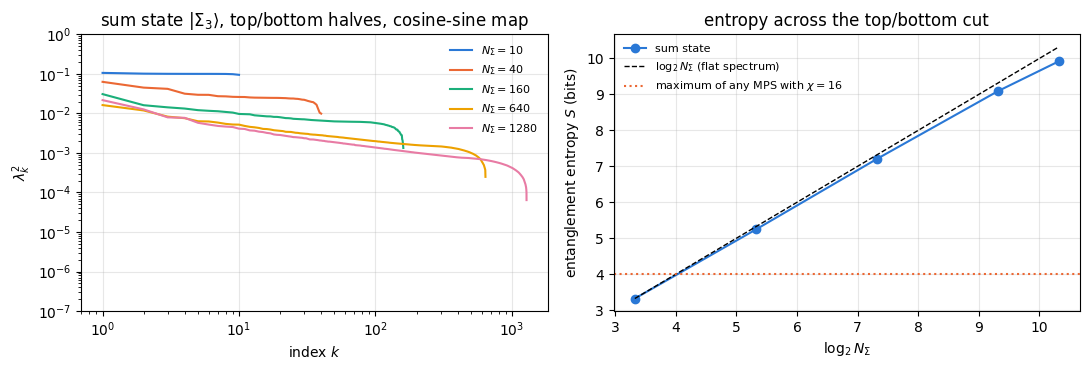

In [26]:
# ==============================================================================
# STEP 16b: Schmidt spectrum of the sum state of Eq. (12) via Eq. (14)
# ==============================================================================


def gram_matrices(phi, cut):
    """Gram matrices X_A, X_B of the parts A = sites < cut and B = sites >= cut of product states phi (M, N, 2)."""
    return gram_product(phi[:, :cut]), gram_product(phi[:, cut:])


def sum_state_schmidt_weights(phi, cut):
    """Squared Schmidt values lambda_k^2 of sum_i |Phi(x_i)> across `cut`, from Eq. (14), sorted decreasingly."""
    XA, XB = gram_matrices(phi, cut)
    ev, U = jnp.linalg.eigh(XA)
    XA_half = (U * jnp.sqrt(jnp.clip(ev, 0.0, None))) @ U.T
    w = jnp.clip(jnp.linalg.eigvalsh(XA_half @ XB @ XA_half)[::-1], 0.0, None)
    return w / jnp.sum(w)


def entropy_bits(w):
    w = np.asarray(w)
    w = w[w > 1e-300]
    return float(-np.sum(w * np.log2(w)))


# CHECKPOINT: Eq. (14) against the SVD of the explicit 2^12-component sum state of a 3 x 4 patch
phi_patch = feature_cos_sin(X_TRAIN[:20][:, patch])                     # 20 images, 12 pixels
psi_patch = jnp.sum(jnp.stack([dense_product_state(p) for p in phi_patch]), axis=0)
sv = jnp.linalg.svd(psi_patch.reshape(2 ** 6, 2 ** 6), compute_uv=False)
w_dense = (sv ** 2 / jnp.sum(sv ** 2))[:20]
w_gram = sum_state_schmidt_weights(phi_patch, 6)
err_gram = max_abs(w_dense - w_gram)
print(f"3x4 patch, 20 images: max |lambda^2 (SVD of the 4096-vector) - lambda^2 (Gram, Eq. 14)| = {err_gram:.1e}")
assert err_gram < 1e3 * TOL

threes = X_TRAIN[Y_TRAIN == 3]
NSIG_LIST = (10, 40, 160, 640, 1280)
W_SUM = {}
for n_sig in NSIG_LIST:
    W_SUM[n_sig] = np.asarray(sum_state_schmidt_weights(feature_cos_sin(threes[:n_sig]), N_SITES // 2))
    n90 = int(np.searchsorted(np.cumsum(W_SUM[n_sig]), 0.9)) + 1
    print(f"digit 3, N_Sigma = {n_sig:4d} images: S = {entropy_bits(W_SUM[n_sig]):6.3f} bits  "
          f"(log2 N_Sigma = {np.log2(n_sig):6.3f}),  largest lambda^2 = {W_SUM[n_sig][0]:.4f},  "
          f"Schmidt values for 90 % of the weight: {n90}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, n_sig in enumerate(NSIG_LIST):
    axes[0].loglog(np.arange(1, n_sig + 1), np.clip(W_SUM[n_sig], 1e-12, None), color=PALETTE[k],
                   label=f"$N_\\Sigma={n_sig}$")
axes[0].set_xlabel("index $k$")
axes[0].set_ylabel(r"$\lambda_k^2$")
axes[0].set_ylim(1e-7, 1)
axes[0].set_title(r"sum state $\vert\Sigma_3\rangle$, top/bottom halves, cosine-sine map")
axes[0].legend(fontsize=8)
axes[1].plot(np.log2(NSIG_LIST), [entropy_bits(W_SUM[n]) for n in NSIG_LIST], "o-", color=PALETTE[0], label="sum state")
axes[1].plot(np.log2(NSIG_LIST), np.log2(NSIG_LIST), "k--", lw=1, label=r"$\log_2 N_\Sigma$ (flat spectrum)")
axes[1].axhline(4.0, color=PALETTE[1], ls=":", label=r"maximum of any MPS with $\chi=16$")
axes[1].set_xlabel(r"$\log_2 N_\Sigma$")
axes[1].set_ylabel("entanglement entropy $S$ (bits)")
axes[1].set_title("entropy across the top/bottom cut")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Interpretation.** Eq. (14) reproduces the Schmidt spectrum of an explicit state of 12 qubits. For the sum state of
the digit 3, the spectrum across the top/bottom cut is almost flat: for $N_\Sigma=10$ all weights are close to
$\frac1{10}$, and the entropy stays close to its maximum $\log_2N_\Sigma$ for all $N_\Sigma$, falling slightly below it
as $N_\Sigma$ grows, because some images begin to overlap. This is the observation of [[3]](#ref-3), Fig. 3: the halves of different images are nearly
orthogonal (Section 4.2), so each image adds its own Schmidt value. An MPS that represents $\vert\Sigma_3\rangle$ to good
accuracy would need a bond dimension comparable to the number of images, about 6000 for the full MNIST class; our
classifier has $\chi=16$, and the one of [[1]](#ref-1) has at most $120$.

### 9.3 Entanglement of the trained classifier

For the classifier of Section 8.3 we fix the label $\ell$, which turns Eq. (5) into an MPS of 196 qubits without a label
leg, and compute its Schmidt values across every bond. A left-to-right
sweep of QR decompositions makes every tensor left-canonical, a right-to-left sweep of SVDs then produces the Schmidt
values of every cut. The norm of the state is collected on the way, in logarithmic form. We also compute the overlap
of the normalised classifier state $\vert W^3\rangle$ with the normalised sum state $\vert\Sigma_3\rangle$ of the 1280
images above, now in the linear map with which the classifier was trained:
$\langle W^3\vert\Sigma_3\rangle=\sum_if^3(\mathbf x_i)$, a sum of the scores, and
$\Vert\Sigma_3\Vert^2=\sum_{i,k}K(\mathbf x_i,\mathbf x_k)$. In a space of $2^{196}$ dimensions any two states have a
tiny overlap, so the number needs a reference: the overlap of the same $\vert W^3\rangle$ with the sum state of 1280
images of the digit 5. In the linear map the product states are not normalised,
$\Vert\Phi(\mathbf x)\Vert^2=\prod_j[(1-x_j)^2+x_j^2]$, which falls exponentially with the number of grey pixels; the
cell prints the spread of these norms.

N = 8: max |Schmidt weights (MPS) - (explicit state)| = 3.3e-16,  |log norm difference| = 8.9e-16



trained classifier, chi = 16: largest entropy over all bonds and labels 2.426 bits (bound log2 16 = 4),  mean over bonds and labels 0.730 bits
entropy across the top/bottom cut (bond 98), labels 0-9: 2.25, 2.05, 2.14, 2.03, 2.19, 2.09, 2.25, 1.95, 2.03, 2.25



squared overlap of the normalised |W^3> with the normalised sum state of 1280 images (linear map):  threes 4.26e-52,  fives 1.21e-53
linear map, 1280 threes: log10 <Phi|Phi> from -12.9 to -4.5 (median -8.4);  the 10 largest carry 50% of sum_i <Phi_i|Phi_i>


sum state of the same 1280 images in the linear map, top/bottom cut: S = 6.164 bits, Schmidt values for 90 % of the weight: 105
bond with the largest entropy (mean over labels): 104  (label site c = 98)


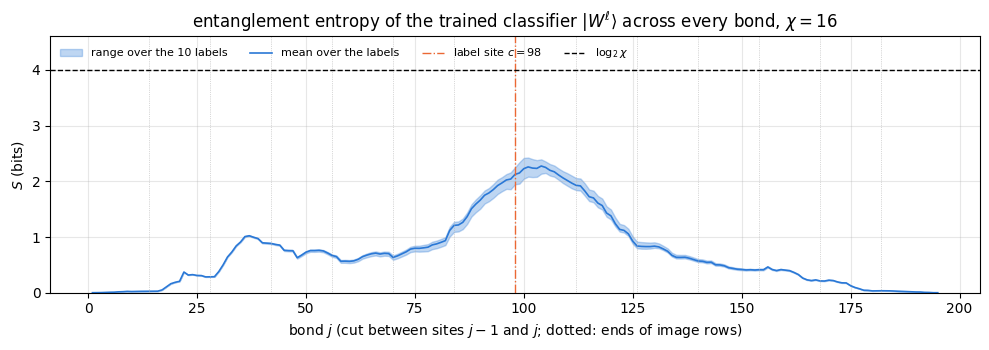

In [27]:
# ==============================================================================
# STEP 17: Schmidt values of the trained classifier for each label; overlap with the sum state
# ==============================================================================
def label_mps(params, ell):
    """List of N tensors (chi_l, 2, chi_r) of the classifier with the label fixed to ell; boundary bonds of size 1."""
    A, lab = np.asarray(params["A"]), np.asarray(params["lab"])
    N = A.shape[0] + 1
    c = N // 2
    T = [A[j] if j < c else A[j - 1] for j in range(N) if j != c]
    T.insert(c, lab[:, :, ell, :])
    T[0], T[-1] = T[0][0:1], T[-1][:, :, 0:1]
    return T


def mps_schmidt_profile(T):
    """Squared Schmidt values across every bond of the MPS T (list of (chi_l, 2, chi_r)), and log of its norm.

    MATH   left sweep:  T_j = Q R (QR of the (chi_l*2, chi_r) matrix), T_j <- Q, T_{j+1} <- R T_{j+1};  the norm ends
           up in the last tensor and is divided out (log kept);  right sweep:  T_j = U S V^dag (SVD of (chi_l, 2*chi_r)),
           S^2 / sum S^2 = Schmidt weights of the cut left of site j,  T_{j-1} <- T_{j-1} U S
    """
    T = [t.copy() for t in T]
    log_norm = 0.0
    for j in range(len(T) - 1):
        a, s, b = T[j].shape
        Q, R = np.linalg.qr(T[j].reshape(a * s, b))
        T[j] = Q.reshape(a, s, -1)
        T[j + 1] = np.einsum("ab,bsc->asc", R, T[j + 1])
        nr = np.linalg.norm(T[j + 1])
        T[j + 1] /= nr
        log_norm += np.log(nr)
    weights = [None] * len(T)
    for j in range(len(T) - 1, 0, -1):
        a, s, b = T[j].shape
        U, S, Vh = np.linalg.svd(T[j].reshape(a, s * b), full_matrices=False)
        T[j] = Vh.reshape(-1, s, b)
        T[j - 1] = np.einsum("asb,bc->asc", T[j - 1], U * S[None, :])
        weights[j] = S ** 2 / np.sum(S ** 2)
    return weights[1:], log_norm                                      # weights[k] = cut between sites k and k+1


# CHECKPOINT: the profile of a small MPS against the Schmidt values of its explicit state (N = 8 chain from Section 5)
T_small = label_mps(p_small, 2)
w_small, ln_small = mps_schmidt_profile(T_small)
psi_small = W_dense[:, 2]
err_prof = 0.0
for k in range(1, N_small):
    svk = np.linalg.svd(np.asarray(psi_small).reshape(2 ** k, -1), compute_uv=False)
    wk = svk ** 2 / np.sum(svk ** 2)
    m = min(len(wk), len(w_small[k - 1]))
    err_prof = max(err_prof, np.max(np.abs(wk[:m] - w_small[k - 1][:m])))
err_lognorm = abs(ln_small - np.log(float(jnp.linalg.norm(psi_small))))
print(f"N = 8: max |Schmidt weights (MPS) - (explicit state)| = {err_prof:.1e},  |log norm difference| = {err_lognorm:.1e}")
assert err_prof < 1e3 * TOL and err_lognorm < 1e3 * TOL

S_PROFILE = {}
for ell in range(N_LABELS):
    w_list, _ = mps_schmidt_profile(label_mps(params_best, ell))
    S_PROFILE[ell] = np.array([entropy_bits(w) for w in w_list])
S_all = np.array(list(S_PROFILE.values()))
print(f"\ntrained classifier, chi = 16: largest entropy over all bonds and labels {S_all.max():.3f} bits "
      f"(bound log2 16 = 4),  mean over bonds and labels {S_all.mean():.3f} bits")
print(f"entropy across the top/bottom cut (bond 98), labels 0-9: "
      + ", ".join(f"{S_PROFILE[l][N_SITES // 2 - 1]:.2f}" for l in range(N_LABELS)))

# overlap of the normalised classifier state |W^3> with normalised sum states of 1280 threes and 1280 fives (linear map)
_, log_norm_W3 = mps_schmidt_profile(label_mps(params_best, 3))


def squared_overlap_W3(phi_set):
    """|<W^3|Sigma>|^2 / (<W^3|W^3> <Sigma|Sigma>) for Sigma = sum of the product states phi_set (M, N, 2)."""
    overlap = float(jnp.sum(scores_batch(params_best, phi_set)[:, 3]))
    norm_sigma = float(jnp.sqrt(jnp.sum(gram_product(phi_set))))
    return (overlap / (np.exp(log_norm_W3) * norm_sigma)) ** 2


phi3 = feature_linear(threes[:1280])
phi5 = feature_linear(X_TRAIN[Y_TRAIN == 5][:1280])
print(f"\nsquared overlap of the normalised |W^3> with the normalised sum state of 1280 images (linear map):  "
      f"threes {squared_overlap_W3(phi3):.2e},  fives {squared_overlap_W3(phi5):.2e}")
log_norm2 = np.sum(np.log10(np.sum(np.asarray(phi3) ** 2, axis=2)), axis=1)    # log10 <Phi|Phi> per image
share = np.sort(10.0 ** log_norm2)[::-1]
print(f"linear map, 1280 threes: log10 <Phi|Phi> from {log_norm2.min():.1f} to {log_norm2.max():.1f} "
      f"(median {np.median(log_norm2):.1f});  the 10 largest carry {share[:10].sum() / share.sum():.0%} of sum_i <Phi_i|Phi_i>")
w_lin = np.asarray(sum_state_schmidt_weights(phi3, N_SITES // 2))
print(f"sum state of the same 1280 images in the linear map, top/bottom cut: S = {entropy_bits(w_lin):.3f} bits, "
      f"Schmidt values for 90 % of the weight: {int(np.searchsorted(np.cumsum(w_lin), 0.9)) + 1}")

bonds = np.arange(1, N_SITES)
print(f"bond with the largest entropy (mean over labels): {bonds[np.argmax(S_all.mean(axis=0))]}  (label site c = {N_SITES // 2})")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(bonds, S_all.min(axis=0), S_all.max(axis=0), color=PALETTE[0], alpha=0.3, label="range over the 10 labels")
ax.plot(bonds, S_all.mean(axis=0), color=PALETTE[0], lw=1.2, label="mean over the labels")
for r in range(1, 14):
    ax.axvline(14 * r, color="0.7", lw=0.5, ls=":")
ax.axvline(N_SITES // 2, color=PALETTE[1], lw=1, ls="-.", label="label site $c=98$")
ax.axhline(4.0, color="k", lw=1, ls="--", label=r"$\log_2\chi$")
ax.set_ylim(0, 4.6)
ax.set_xlabel("bond $j$ (cut between sites $j-1$ and $j$; dotted: ends of image rows)")
ax.set_ylabel("$S$ (bits)")
ax.set_title(r"entanglement entropy of the trained classifier $\vert W^{\ell}\rangle$ across every bond, $\chi=16$")
ax.legend(fontsize=8, ncol=4, loc="upper left")
fig.tight_layout()
plt.show()

**Interpretation.** The Schmidt values computed from the MPS agree with those of the explicit state for the
8-site test chain. The trained classifier uses only part of the entanglement its bond dimension allows: the largest
entropy over all bonds and labels is $2.43$ bits, against the bound $\log_2 16=4$, and the mean is $0.73$ bits. The
entropy is zero near the ends of the chain, where the image is white and the classifier carries no information, has a
first maximum of about one bit near bond 35 (row 2, the top of the digits) and its largest values, 2 to 2.4 bits, a
few bonds after the label site $c=98$ (maximum at the bond printed above). Around the label site the bonds carry what
the rest of the image says about all ten labels. The profiles of the ten labels are almost the same, because they
share all tensors except the label tensor.

The sum state is a different object. In the cosine–sine map its entropy across the middle cut is $9.9$ bits for 1280
images (Section 9.2). In the linear map the product states are not normalised: their norms squared range over more
than eight decades (printed above), and a few images with few grey pixels dominate the sum, with $50\,\%$ of the total
norm in the 10 largest. The entropy of this sum is $6.2$ bits, and 105 Schmidt values are needed for $90\,\%$ of the
weight, far more than $\chi=16$. The squared overlap of the normalised classifier state $\vert W^3\rangle$ with the
normalised sum state of the threes is $4\times10^{-52}$, 35 times its overlap with the sum state of the fives,
$1.2\times10^{-53}$: the classifier state is closer to its own class, and both numbers are tiny. The classifier is a much less entangled state
than the superposition of its training images, and it still assigns the largest score to the right label for most
images. This is the first conclusion of [[3]](#ref-3), here for $14\times14$ images and a classifier trained by
automatic differentiation.

**Pixel ordering.** In the row-by-row order the cut between the top and bottom halves of the image is a single bond,
and pixels that are neighbours in the same column are 14 sites apart. All correlations between the upper and the
lower half of a digit pass through one bond of dimension $\chi$, and correlations between vertically neighbouring
pixels must be carried along 14 bonds. Other orderings change which correlations are short-ranged in the chain;
[[3]](#ref-3), Sec. IV, goes further and replaces the MPS by products of small blocks of $n\times n$ pixels, which keep
the entanglement local in two dimensions (Exercise 4 compares two orderings).

In [28]:
section_timer("10 cost")

## 10. Cost of the computation

| operation | cost | here |
|---|---|---|
| scores of one image, Eq. (6), sequential | $O(N\chi^2)$ | Sections 5, 7 |
| scores of one image, pairwise order | $O(N\chi^3)$ in $\log_2N$ rounds | Section 7.2 |
| one sweep: $2(N-1)$ bonds, each $k$ gradient steps on $N_{\rm T}$ images | $O(NkN_{\rm T}\chi^2\cdot10)$ plus $2(N-1)$ SVDs of $O(\chi^3\cdot10)$ | Section 6 |
| one epoch of Adam: forward and backward pass on $N_{\rm T}$ images | $O(N_{\rm T}N\chi^2)$ | Section 7 |
| memory of the cached environments of the sweep | $(2N+1)N_{\rm T}\chi$ numbers | Section 6.5 |
| Schmidt spectrum of a sum of $N_\Sigma$ product states | $O(N_\Sigma^2N+N_\Sigma^3)$ | Section 9.2 |

The cached environments of the sweep are among the largest arrays of the notebook; the cell prints the size of the
arrays `Lst` and `Rst` of the run of Section 6.7 and the wall-clock time of every section.

In [29]:
# ==============================================================================
# STEP 18: time per section
# ==============================================================================
print(f"cached environments of the sweep (Lst + Rst, chi = {CHI_SWEEP}, {N_TRAIN_SWEEP} images): {hist_sw[0]['env_MB']:.0f} MB")
section_timer("end")
print("\nwall-clock time per section:")
for k, v in SECTION_TIMES.items():
    if k != "end":
        print(f"   {k:28s} {v:6.1f} s")
print(f"   {'total (Sections 3-10)':28s} {sum(v for k, v in SECTION_TIMES.items() if k != 'end'):6.1f} s")

cached environments of the sweep (Lst + Rst, chi = 8, 5000 images): 126 MB

wall-clock time per section:
   3 data                          0.4 s
   4 feature maps                  1.4 s
   5 MPS classifier                5.8 s
   6 DMRG sweeps                  35.9 s
   7 automatic differentiation    31.2 s
   8 results                     108.2 s
   9 entanglement                 16.3 s
   10 cost                         0.0 s
   total (Sections 3-10)         199.2 s


The training runs of Section 8 take most of the time; the sweeps of Section 6 come next. The entanglement analysis
is cheap, because Eq. (14) never forms a vector of $2^{196}$ components.

## 11. Limits of the method

* **One-dimensional structure for two-dimensional data.** An MPS orders the pixels on a line. Correlations between
  pixels that are neighbours in the image but far apart in the chain must be carried by many bonds, and all
  correlations between the top and the bottom half pass through one bond (Section 9.3). Tensor networks built for two
  dimensions are more natural for images, at a higher cost of contraction; [[1]](#ref-1), Sec. IX, names PEPS as an
  option, and [[3]](#ref-3) uses products of two-dimensional blocks.
* **Sensitivity to scale.** The score is a product of 196 factors. Without rescaling it overflows (Section 5.3), and a
  poorly scaled initial MPS, or a feature map whose components do not add to one, leaves the training with a
  badly conditioned start (Section 7.3).
* **Generalisation.** A large bond dimension is not an advantage by itself: the accuracy saturates with $\chi$ and
  the gap between training and test accuracy is set by the number of training images (Section 8.2). [[3]](#ref-3)
  finds models with very high training accuracy and noticeably lower test accuracy.
* **Training is not convex.** Both methods find local minima of a non-convex cost; the result depends on the
  initial MPS, the learning rate and, for the sweep, the number of steps per bond.
* **The model is classical.** It runs on a CPU, its cost is polynomial in $N$ and $\chi$, and nothing in it requires
  or demonstrates a quantum computer. The quantum language is a description of the linear algebra.

## 12. Key takeaways

* **The model.** An image of $N$ pixels becomes a product state of $N$ qubits; a linear model on these states needs a
  weight tensor with $10\times2^N$ components; written as an MPS with a label leg, it has $O(N\chi^2)$ parameters and
  costs $O(N\chi^2)$ per image (Eqs. (1)–(6)).
* **Kernel.** The feature map defines the product kernel $\prod_j\cos\frac{\pi(x_j-x'_j)}2$; different images are
  nearly orthogonal states.
* **Sweeps are DMRG.** The sweeping algorithm merges two sites into a bond tensor, updates it with a few gradient
  steps using the cached environments of all training images, splits it by an SVD and moves the label with the
  orthogonality centre. Small steps keep the discarded weight small (below $10^{-2}$ in our run).
* **Autodiff computes environments.** The gradient of a contraction with respect to one tensor is its environment
  (checked to round-off); reverse-mode differentiation computes them for all tensors in one backward pass. Keep $\chi$
  fixed, do not differentiate through truncated SVDs, rescale long products and track $\log Z$.
* **Results.** On $14\times14$ MNIST, three sweeps reached $86.9\,\%$ and six epochs of Adam $93.2\,\%$ ($\chi=8$, 5000
  images); our best model, $\chi=16$ and 20000 images, $96.3\,\%$, in under a minute of CPU time. The accuracy
  saturates in $\chi$ and grows with the training set, consistent with the published $98\,\%$ on 60000 images. With a
  single label leg, $\chi=1$ cannot classify at all.
* **Entanglement.** The superposition of the training images of a class has an almost flat Schmidt spectrum and
  entropy close to $\log_2N_\Sigma$; the trained classifier carries at most $2.4$ bits and has a squared overlap of
  $4\times10^{-52}$ with that superposition. A good classifier is a weakly entangled state, far from the sum of its
  examples.

## 13. Exercises

1. ★ **Parameter count.** Show that the classifier of Eq. (5) with uniform bond dimension $\chi$ has
   $2\chi^2(N-1)+20\chi^2$ parameters in our storage, and that the true number is smaller because the first and last
   tensors use only one row and one column. Compare with a fully connected network with one hidden layer of 100 units
   on 196 pixels.
2. ★ **The quadratic cost in the sweep.** Replace the cross-entropy in `local_update` by the quadratic cost of
   [[1]](#ref-1), Eq. (6); its gradient is $\tilde\Phi^{\rm T}(\tilde\Phi\mathbf B-Y)/N_{\rm T}$ and its curvature exactly
   $\lambda_{\max}(\tilde\Phi^{\rm T}\tilde\Phi)/N_{\rm T}$.
   Run three sweeps and compare the test accuracy with Section 6.7. Then fit the bond tensor exactly by least squares
   and observe what the truncation does to the cost.
3. ★★ **The cosine–sine map (extend the code).** Train with `feature_cos_sin` by automatic differentiation, starting from
   `init_mps_params`, for six epochs. Then rescale the initial site tensors, $A^{[j]0}=A^{[j]1}=\mathbb 1/\sqrt2$, and
   show that this shifts all initial scores by the same factor $2^{-(N-1)/2}$ but leaves their spread over images
   unchanged (Section 7.3). Finally divide the scores of each image by $\prod_j(\cos\frac{\pi x_j}2+\sin\frac{\pi x_j}2)$
   before the softmax, which is the same as training with the feature map
   $\phi(x)/(\cos\frac{\pi x}2+\sin\frac{\pi x}2)$, and compare the three runs.
4. ★★ **Pixel ordering.** Train the $\chi=8$ classifier with the pixels in column-by-column order, in a snake order
   (rows alternately left to right and right to left) and in a random order, and compare the test accuracies and the
   entanglement profiles of Section 9.3. Which correlations does each ordering make short-ranged?
5. ★★ **Fashion-MNIST.** Repeat the study of Section 8.1 on Fashion-MNIST (`../data/fashion_mnist_14x14.npz`). Does
   the accuracy saturate at the same $\chi$ as for the digits?
6. ★★ **Generative interpretation (physics).** [[1]](#ref-1), Sec. VIII.C, proposes to read $\vert f^\ell(\mathbf x)\vert^2$
   as a probability distribution of images of class $\ell$. This requires
   $\sum_\ell\int\vert f^\ell(\mathbf x)\vert^2d\mu(\mathbf x)=\sum_\ell\Vert W^\ell\Vert^2$, which holds for every $W$ if
   the local map is orthonormal, $\int_0^1\bar\phi_s(x)\phi_{s'}(x)\,d\mu(x)=\delta_{ss'}$. With $d\mu=2\,dx$, compute the
   integrals for the cosine–sine map (the off-diagonal one is $2/\pi$), and show that the complex map
   $\phi(x)=\big(e^{i3\pi x/2}\cos\frac{\pi x}2,\ e^{-i3\pi x/2}\sin\frac{\pi x}2\big)$, Eq. (23) of [[1]](#ref-1), is
   orthonormal.
7. ★★★ **Sampling digits.** With the map of Exercise 6 and $\sum_\ell\Vert W^\ell\Vert^2=1$,
   $p(\ell,\mathbf x)=\vert f^\ell(\mathbf x)\vert^2$ is a normalised distribution. Fix one label and train its MPS on the
   images of one digit by minimising $-\sum_i\log\vert f(\mathbf x_i)\vert^2$ ([[1]](#ref-1), Eq. (24)) while keeping
   $\Vert W\Vert=1$. Then sample new images exactly, pixel by pixel: in right-canonical form the marginal of pixel 0 is
   $p(x_0)=\Vert\sum_s\phi_s(x_0)A^{[0]s}\Vert^2$ (with the measure $2\,dx$), and each further pixel is drawn from its conditional distribution given the
   pixels already drawn (the bit-string sampling of an MPS).
8. ★★★ **Automatic differentiation for a ground state.** Use the same machinery for physics: write
   $E(A)=\langle\psi\vert H\vert\psi\rangle/\langle\psi\vert\psi\rangle$ for an MPS $\vert\psi\rangle$ of the XXZ
   chain with the MPO of [notebook 18, matrix product states](../ch07_tensor_networks/18_mps_tebd.ipynb), Section 6.2,
   minimise it with `jax.grad` and Adam, and compare the energy and the cost with DMRG at the same $\chi$. Gradient-based optimisation of tensor networks by automatic
   differentiation is developed in [[8]](#ref-8), which applies it to infinite PEPS.
9. ★★ **Boundary rows in the sweep (extend the code).** Set the rows $a\neq0$ of the centre tensor on site 0 and the
   columns $b\neq0$ of the tensor on site $N-1$ to zero at the start and after every split (Section 6.6), so that the
   SVDs see only entries that images reach. Run three sweeps and compare the cost, the discarded weight and the test
   accuracy with Section 6.7. How many bond directions have a non-zero singular value after the first split at each
   end, with and without the zeroed entries?

## References

<span id="ref-1">[1]</span> E. M. Stoudenmire and D. J. Schwab, *Supervised learning with tensor networks*, Advances in
Neural Information Processing Systems 29 (2016); extended version *Supervised learning with quantum-inspired tensor
networks*, arXiv:1605.05775v2 (2017). Sections, equations and figures are cited from the arXiv version — the MPS classifier:
the local feature map (Eq. (3)), the MPS weight tensor with a label index (Eq. (5)), the quadratic cost (Eq. (6)), the
sweeping algorithm with bond tensor, gradient step, SVD split and moving label (Sec. V, Eqs. (7)–(11), Figs. 6–7), the
$14\times14$ MNIST test and the row-by-row ordering (Sec. VI, Fig. 8), the kernel and generative interpretations
(Secs. II, VIII).

<span id="ref-2">[2]</span> S. Efthymiou, J. Hidary and S. Leichenauer, *TensorNetwork for machine learning*,
arXiv:1906.06329 (2019) — training by automatic differentiation with Adam and the cross-entropy (Sec. II B, Eq. (3), Sec. II D),
the linear feature map (Sec. II A), the pairwise contraction order (Fig. 4), and the results of $98\,\%$ on MNIST and
$88\,\%$ on Fashion-MNIST (Sec. III, Figs. 5–7).

<span id="ref-3">[3]</span> J. Martyn, G. Vidal, C. Roberts and S. Leichenauer, *Entanglement and tensor networks for
supervised image classification*, arXiv:2007.06082 (2020) — the sum state of a class (Eq. (10)), its nearly flat
Schmidt spectrum across the top/bottom cut (Sec. III, Fig. 3), the Gram-matrix method (Appendix A), and block product
states (Sec. IV).

<span id="ref-4">[4]</span> Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, *Gradient-based learning applied to document
recognition*, Proc. IEEE **86**, 2278 (1998) — the MNIST database (Sec. III-A).

<span id="ref-5">[5]</span> S. R. White, *Density matrix formulation for quantum renormalization groups*, Phys. Rev.
Lett. **69**, 2863 (1992) — DMRG.

<span id="ref-6">[6]</span> C. Eckart and G. Young, *The approximation of one matrix by another of lower rank*,
Psychometrika **1**, 211 (1936) — optimality of the truncated SVD.

<span id="ref-7">[7]</span> D. P. Kingma and J. Ba, *Adam: a method for stochastic optimization*, 3rd International
Conference on Learning Representations (ICLR 2015), arXiv:1412.6980 — the optimiser of Section 7.

<span id="ref-8">[8]</span> H.-J. Liao, J.-G. Liu, L. Wang and T. Xiang, *Differentiable programming tensor networks*,
Phys. Rev. X **9**, 031041 (2019), arXiv:1903.09650 — backward rules for the SVD and their instability at degenerate
singular values (Sec. III A, Eq. (4)), checkpointing (Sec. III B), and gradient-based optimisation of tensor networks.

<span id="ref-9">[9]</span> H. Xiao, K. Rasul and R. Vollgraf, *Fashion-MNIST: a novel image dataset for benchmarking
machine learning algorithms*, arXiv:1708.07747 (2017) — the Fashion-MNIST data set.

---
Marcin Płodzień, PhD

**Citation:** M. Płodzień, *Quantum Many-Body Simulation: from a single spin to quantum machine learning* (2026), https://marcinplodzien.github.io/quantum-many-body-simulation/